# BRB-seq differential-expression analysis and QC

Run `BRB_WGS_sample_ID_QC.ipynb` first to generate the QC metadata. This notebook compares deep non-UMI gene counts with deep UMI-deduplicated counts and makes separate gill and liver PCA plots using those baseline calls. After reviewing the PCA at the end, the final cell applies the two sex corrections and writes the definitive `*_FINAL_BRB.tsv` metadata for downstream differential-expression analysis.

QC metadata provide sample/barcode mapping, labels, exclusions, and baseline sex annotations. Review the gill PCA near the end of this notebook; then run the final cell to apply `2025_DJR_196` = female and `2024_DJR_196` = male, record `manual_PCA_review` and the evidence note, and write the definitive metadata files.

> **Admixture exclusion note:** Exclude the following fish from the focal ecotype-divergence differential-expression comparisons because admixture analyses identify clear F1 or early-backcross ancestry. Keep them in the underlying count/QC data; apply exclusions to the relevant analysis sample sets, not by deleting source records.
>
> - `2025_DJR_475`: approximately 1/2 lake, 1/2 stream (WGS, gill, and liver).
> - `2025_DJR_464`: approximately 1/4 lake, 3/4 stream (WGS, gill, and liver).
> - `2024_DJR_427`: anomalous ancestry within an otherwise fully marine group (all datasets).
> - `2024_DJR_122`: approximately 1/2 limnetic, 1/2 benthic (all datasets).
> - `2024_DJR_109`: approximately 1/4 benthic, 3/4 limnetic (all datasets).
> - `2024_DJR_084` and `2024_DJR_045`: each approximately 1/4 limnetic, 3/4 benthic (all datasets).

In [1]:
library(DESeq2)
library(Matrix)
library(ggplot2)

# Edit these paths only if the repository/output location changes.
repo_root <- "/scratch/ztobias/Gacu_BC_txmics"
star_root <- file.path(repo_root, "outputs", "star")
derived_dir <- file.path(repo_root, "metadata", "derived")
metadata_file <- file.path(derived_dir, "sample_source_mapping_QC_BRB.tsv")
decision_log_file <- file.path(derived_dir, "sample_matching_decision_log_QC_BRB.tsv")
barcode_file <- file.path(repo_root, "metadata", "brb_sample_barcodes.tsv")

if (!file.exists(metadata_file)) {
  stop("Missing QC BRB metadata. Run BRB_WGS_sample_ID_QC.ipynb first: ", metadata_file)
}
tracking <- read.delim(metadata_file, header = TRUE, sep = "\t",
  stringsAsFactors = FALSE, check.names = FALSE)
decision_log <- read.delim(decision_log_file, header = TRUE, sep = "\t", stringsAsFactors = FALSE)
tracking$sample_id <- tracking$analysis_id
tracking$ecotype <- tolower(trimws(tracking$ecotype))
tracking$ecotype_plot <- tolower(trimws(tracking$ecotype_plot))
has_final_sex <- !is.na(tracking$final_sex) & tracking$final_sex %in% c("male", "female")
tracking$plot_sex <- ifelse(has_final_sex, tracking$final_sex, "unknown")
if (anyDuplicated(tracking$sample_id)) stop("Duplicate sample IDs in final metadata")
if (anyNA(tracking$ecotype_plot) || any(!nzchar(tracking$ecotype_plot))) {
  stop("Missing plot-ready ecotype in final metadata")
}

# Use corrected IDs and barcodes together so tissue-specific swaps and
# exclusions from final metadata are reflected in the count matrices.
brb_barcodes <- tracking[, c("sample_id", "tissue", "year", "barcode")]
source_barcodes <- read.delim(barcode_file, header = TRUE, sep = "\t", stringsAsFactors = FALSE, check.names = FALSE)
barcode_key <- paste(brb_barcodes$tissue, brb_barcodes$year, brb_barcodes$barcode, sep = "_")
if (anyDuplicated(barcode_key[!is.na(brb_barcodes$barcode)])) {
  stop("Barcode is duplicated within a tissue/year in final BRB metadata")
}
head(tracking[, c("sample_id", "population", "ecotype", "ecotype_plot", "field_sex_recorded", "genetic_sex", "pcr_sex", "final_sex", "final_sex_source", "sex_assignment_confident")])

Loading required package: S4Vectors

Warning message:
“package ‘S4Vectors’ was built under R version 4.1.3”
Loading required package: stats4

Loading required package: BiocGenerics


Attaching package: ‘BiocGenerics’


The following objects are masked from ‘package:stats’:

    IQR, mad, sd, var, xtabs


The following objects are masked from ‘package:base’:

    anyDuplicated, append, as.data.frame, basename, cbind, colnames,
    dirname, do.call, duplicated, eval, evalq, Filter, Find, get, grep,
    grepl, intersect, is.unsorted, lapply, Map, mapply, match, mget,
    order, paste, pmax, pmax.int, pmin, pmin.int, Position, rank,
    rbind, Reduce, rownames, sapply, setdiff, sort, table, tapply,
    union, unique, unsplit, which.max, which.min



Attaching package: ‘S4Vectors’


The following objects are masked from ‘package:base’:

    expand.grid, I, unname


Loading required package: IRanges

Warning message:
“package ‘IRanges’ was built under R version 4.1.3”
Loading required packag

,sample_id,population,ecotype,ecotype_plot,field_sex_recorded,genetic_sex,pcr_sex,final_sex,final_sex_source,sex_assignment_confident
,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<lgl>
1,2024_DJR_346_G,Amor,lake,lake,M,male,,male,WGS,TRUE
2,2024_DJR_347_G,Amor,lake,lake,M,male,,male,WGS,TRUE
3,2024_DJR_348_G,Amor,lake,lake,M,male,,male,WGS,TRUE
4,2024_DJR_349_G,Amor,lake,lake,M,male,,male,WGS,TRUE
5,2024_DJR_350_G,Amor,lake,lake,F,female,,female,WGS,TRUE
6,2024_DJR_351_G,Amor,lake,lake,M,male,,male,WGS,TRUE


## Read and map STAR's deep gene-count and UMI-count matrices

Each year/tissue run has its own STARsolo matrix. The 2025 gill and liver matrices already represent the independent tissue run plus the combined lane, because those FASTQs were concatenated before STAR. STAR was run with `NoDedup 1MM_Directional`, so the two matrices are `umiDedup-NoDedup.mtx` and `umiDedup-1MM_Directional.mtx`.

In [2]:
read_star_matrix <- function(matrix_path) {
  if (!file.exists(matrix_path)) stop("Missing STAR matrix: ", matrix_path)
  raw_dir <- dirname(matrix_path)
  barcode_path <- file.path(raw_dir, "barcodes.tsv")
  feature_path <- file.path(raw_dir, "features.tsv")
  x <- as.matrix(readMM(matrix_path))
  features <- read.delim(feature_path, header = FALSE, sep = "\t",
    stringsAsFactors = FALSE, check.names = FALSE)
  barcodes <- readLines(barcode_path)
  rownames(x) <- make.unique(features[[1]])
  colnames(x) <- barcodes
  storage.mode(x) <- "numeric"
  x
}

matrix_file <- function(tissue, year, mode = c("gene", "umi")) {
  mode <- match.arg(mode)
  prefix <- file.path(star_root, paste0(tissue, "_", year, "_deep_Solo.out"), "Gene", "raw")
  file.path(prefix, if (mode == "gene") "umiDedup-NoDedup.mtx" else "umiDedup-1MM_Directional.mtx")
}

map_matrix_to_samples <- function(x, tissue, year) {
  map <- brb_barcodes[brb_barcodes$tissue == tissue &
    brb_barcodes$year == as.integer(year), c("sample_id", "barcode")]
  if (anyDuplicated(map$barcode)) stop("Duplicate target barcodes for ", tissue, " ", year)
  absent_target_barcodes <- setdiff(map$barcode, colnames(x))
  if (length(absent_target_barcodes)) {
    stop(length(absent_target_barcodes), " final-metadata barcodes absent from STAR matrix for ", tissue, " ", year, ": ", paste(head(absent_target_barcodes, 10), collapse = ", "))
  }
  sample_names <- map$sample_id[match(colnames(x), map$barcode)]
  extra_barcodes <- colnames(x)[is.na(sample_names)]
  source_context <- vapply(extra_barcodes, function(b) any(source_barcodes$barcode == b), logical(1))
  other_context <- vapply(extra_barcodes, function(b) any(source_barcodes$barcode == b &
    (source_barcodes$tissue != tissue | source_barcodes$year != as.integer(year))), logical(1))
  same_context_excluded <- vapply(extra_barcodes, function(b) any(source_barcodes$barcode == b &
    source_barcodes$tissue == tissue & source_barcodes$year == as.integer(year)), logical(1))
  cat(tissue, year, ": mapped ", sum(!is.na(sample_names)), "/", nrow(map),
    " final samples; excluded extra barcode columns: ", length(extra_barcodes),
    " (known other context ", sum(other_context), ", known same-context nonfinal ",
    sum(same_context_excluded), ", unrecognized ", sum(!source_context), " )\n", sep = "")
  keep <- !is.na(sample_names)
  x <- x[, keep, drop = FALSE]
  colnames(x) <- sample_names[keep]
  if (anyDuplicated(colnames(x)) || !setequal(colnames(x), map$sample_id)) {
    stop("Mapped count-matrix IDs do not exactly cover final metadata for ", tissue, " ", year)
  }
  x
}

read_tissue_counts <- function(tissue, mode = c("gene", "umi")) {
  mode <- match.arg(mode)
  mats <- lapply(c("2024", "2025"), function(year) {
    x <- read_star_matrix(matrix_file(tissue, year, mode))
    map_matrix_to_samples(x, tissue, year)
  })
  genes <- Reduce(intersect, lapply(mats, rownames))
  mats <- lapply(mats, function(x) x[genes, , drop = FALSE])
  out <- do.call(cbind, mats)
  if (anyDuplicated(colnames(out))) stop("Duplicate sample IDs in ", tissue, " matrix")
  out
}

gill_gene_counts <- read_tissue_counts("gill", "gene")
liver_gene_counts <- read_tissue_counts("liver", "gene")
gill_umi_counts <- read_tissue_counts("gill", "umi")
liver_umi_counts <- read_tissue_counts("liver", "umi")

# The gene and UMI matrices should contain the same sample and gene sets.
stopifnot(identical(dim(gill_gene_counts), dim(gill_umi_counts)))
stopifnot(identical(dim(liver_gene_counts), dim(liver_umi_counts)))
dim(gill_gene_counts)
dim(liver_gene_counts)

gill2024: mapped 370/370 final samples; excluded extra barcode columns: 14 (known other context 14, known same-context nonfinal 5, unrecognized 0 )
gill2025: mapped 255/255 final samples; excluded extra barcode columns: 129 (known other context 83, known same-context nonfinal 0, unrecognized 46 )
liver2024: mapped 367/367 final samples; excluded extra barcode columns: 17 (known other context 17, known same-context nonfinal 8, unrecognized 0 )
liver2025: mapped 264/264 final samples; excluded extra barcode columns: 120 (known other context 74, known same-context nonfinal 0, unrecognized 46 )
gill2024: mapped 370/370 final samples; excluded extra barcode columns: 14 (known other context 14, known same-context nonfinal 5, unrecognized 0 )
gill2025: mapped 255/255 final samples; excluded extra barcode columns: 129 (known other context 83, known same-context nonfinal 0, unrecognized 46 )
liver2024: mapped 367/367 final samples; excluded extra barcode columns: 17 (known other context 17, kno

[1] 28136   625

[1] 28136   631

In [3]:
make_coldata <- function(counts) {
  md <- tracking[match(colnames(counts), tracking$sample_id), , drop = FALSE]
  if (anyNA(md$sample_id)) stop("Count matrix sample missing from compiled metadata")
  rownames(md) <- md$sample_id
  md
}

gill_metadata <- make_coldata(gill_gene_counts)
liver_metadata <- make_coldata(liver_gene_counts)

# Final sex is WGS, PCR/BOTH, or exact M/F field fallback; source stays explicit.
gill_metadata[gill_metadata$sample_id == "2024_DJR_196_G",
  c("sample_id", "field_sex_recorded", "genetic_sex", "pcr_sex", "final_sex", "final_sex_source", "population", "ecotype_plot")]

gill_metadata[is.na(gill_metadata$final_sex) | gill_metadata$final_sex == "",
  c("sample_id", "field_sex_recorded", "genetic_sex", "pcr_sex", "final_sex", "final_sex_source", "population", "ecotype_plot")]

gill_metadata[is.na(gill_metadata$ecotype_plot) | gill_metadata$ecotype_plot == "",
  c("sample_id", "population", "ecotype", "ecotype_plot")]

table(gill_metadata$final_sex_source, useNA = "ifany")

table(gill_metadata$year, useNA = "ifany")
table(liver_metadata$year, useNA = "ifany")

,sample_id,field_sex_recorded,genetic_sex,pcr_sex,final_sex,final_sex_source,population,ecotype_plot
,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>
2024_DJR_196_G,2024_DJR_196_G,?,,,,,Boot,lake


,sample_id,field_sex_recorded,genetic_sex,pcr_sex,final_sex,final_sex_source,population,ecotype_plot
,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>
2024_DJR_196_G,2024_DJR_196_G,?,,,,,Boot,lake


sample_id,population,ecotype,ecotype_plot
<chr>,<chr>,<chr>,<chr>



      field   WGS 
    1     5   619 


2024 2025 
 370  255 


2024 2025 
 367  264 

## Gene-count versus UMI-count comparison

First compare total counts retained after UMI deduplication. A lower UMI/gene ratio indicates more PCR duplication. The population summaries are descriptive only; they show whether deduplication affects populations differently before choosing the expression matrix for PCA.

In [4]:
# Inspect the matrices before giving them to DESeq2.
count_diagnostics <- function(counts, label) {
  cat("\n--- ", label, " ---\n")
  cat("dimensions: ", nrow(counts), " genes x ", ncol(counts), " samples\n")
  cat("NA values: ", sum(is.na(counts)), "\n")
  cat("negative values: ", sum(counts < 0, na.rm = TRUE), "\n")
  cat("all-zero genes: ", sum(rowSums(counts) == 0), "\n")
  cat("all-zero samples: ", sum(colSums(counts) == 0), "\n")
  sample_summary <- data.frame(
    sample = colnames(counts),
    total_counts = colSums(counts),
    detected_genes = colSums(counts > 0),
    zero_genes = colSums(counts == 0)
  )
  print(summary(sample_summary$total_counts))
  print(summary(sample_summary$detected_genes))
  print(sample_summary[order(sample_summary$total_counts), ])
  invisible(sample_summary)
}

gill_gene_diagnostics <- count_diagnostics(gill_gene_counts, "gill gene")
liver_gene_diagnostics <- count_diagnostics(liver_gene_counts, "liver gene")
gill_umi_diagnostics <- count_diagnostics(gill_umi_counts, "gill UMI")
liver_umi_diagnostics <- count_diagnostics(liver_umi_counts, "liver UMI")


---  gill gene  ---
dimensions:  28136  genes x  625  samples
NA values:  0 
negative values:  0 
all-zero genes:  3807 
all-zero samples:  0 
   Min. 1st Qu.  Median    Mean 3rd Qu.    Max. 
 223225 2586932 2850603 2809198 3070073 6129952 
   Min. 1st Qu.  Median    Mean 3rd Qu.    Max. 
  12225   15737   16222   16574   17665   19616 
                       sample total_counts detected_genes zero_genes
2025_DJR_267_G 2025_DJR_267_G       223225          12225      15911
2025_DJR_286_G 2025_DJR_286_G       360418          13589      14547
2025_DJR_254_G 2025_DJR_254_G       497571          14586      13550
2025_DJR_263_G 2025_DJR_263_G       517747          14410      13726
2025_DJR_266_G 2025_DJR_266_G       522012          13857      14279
2025_DJR_276_G 2025_DJR_276_G       672652          15605      12531
2025_DJR_052_G 2025_DJR_052_G       988416          16137      11999
2025_DJR_018_G 2025_DJR_018_G      1088971          16158      11978
2025_DJR_265_G 2025_DJR_265_G      1116


---  liver gene  ---
dimensions:  28136  genes x  631  samples
NA values:  0 
negative values:  0 
all-zero genes:  4146 
all-zero samples:  0 
   Min. 1st Qu.  Median    Mean 3rd Qu.    Max. 
 310024 1815842 1997909 2179577 2611423 7050734 
   Min. 1st Qu.  Median    Mean 3rd Qu.    Max. 
   7751   12168   12718   12683   13265   16753 
                       sample total_counts detected_genes zero_genes
2024_DJR_094_L 2024_DJR_094_L       310024           7751      20385
2024_DJR_039_L 2024_DJR_039_L       383977           7966      20170
2024_DJR_105_L 2024_DJR_105_L       397768           9643      18493
2024_DJR_295_L 2024_DJR_295_L       505020          10724      17412
2024_DJR_085_L 2024_DJR_085_L       614961           9812      18324
2024_DJR_097_L 2024_DJR_097_L       649092          10668      17468
2024_DJR_009_L 2024_DJR_009_L       694703           9070      19066
2024_DJR_407_L 2024_DJR_407_L       696586           9056      19080
2024_DJR_114_L 2024_DJR_114_L       79


---  gill UMI  ---
dimensions:  28136  genes x  625  samples
NA values:  0 
negative values:  0 
all-zero genes:  3807 
all-zero samples:  0 
   Min. 1st Qu.  Median    Mean 3rd Qu.    Max. 
 154412  801115  919327 1218182 1769174 4227987 
   Min. 1st Qu.  Median    Mean 3rd Qu.    Max. 
  12225   15737   16222   16574   17665   19616 
                       sample total_counts detected_genes zero_genes
2025_DJR_267_G 2025_DJR_267_G       154412          12225      15911
2025_DJR_286_G 2025_DJR_286_G       257644          13589      14547
2025_DJR_254_G 2025_DJR_254_G       358284          14586      13550
2025_DJR_266_G 2025_DJR_266_G       359173          13857      14279
2025_DJR_263_G 2025_DJR_263_G       366493          14410      13726
2024_DJR_121_G 2024_DJR_121_G       432956          15012      13124
2024_DJR_287_G 2024_DJR_287_G       462964          15118      13018
2024_DJR_288_G 2024_DJR_288_G       463657          15468      12668
2025_DJR_276_G 2025_DJR_276_G       4873


---  liver UMI  ---
dimensions:  28136  genes x  631  samples
NA values:  0 
negative values:  0 
all-zero genes:  4146 
all-zero samples:  0 
   Min. 1st Qu.  Median    Mean 3rd Qu.    Max. 
 140468 1007554 1144678 1095528 1227442 3103504 
   Min. 1st Qu.  Median    Mean 3rd Qu.    Max. 
   7751   12168   12718   12683   13265   16753 
                       sample total_counts detected_genes zero_genes
2024_DJR_094_L 2024_DJR_094_L       140468           7751      20385
2024_DJR_039_L 2024_DJR_039_L       175916           7966      20170
2024_DJR_105_L 2024_DJR_105_L       204832           9643      18493
2024_DJR_295_L 2024_DJR_295_L       256886          10724      17412
2024_DJR_085_L 2024_DJR_085_L       291846           9812      18324
2024_DJR_009_L 2024_DJR_009_L       299195           9070      19066
2024_DJR_097_L 2024_DJR_097_L       310168          10668      17468
2024_DJR_407_L 2024_DJR_407_L       317705           9056      19080
2024_DJR_114_L 2024_DJR_114_L       369

In [5]:
summarize_count_ratio <- function(gene_counts, umi_counts, metadata, tissue) {
  stopifnot(identical(rownames(gene_counts), rownames(umi_counts)))
  stopifnot(identical(colnames(gene_counts), colnames(umi_counts)))
  sample_metadata <- metadata[match(colnames(gene_counts), metadata$sample_id), , drop = FALSE]
  total_gene <- colSums(gene_counts)
  total_umi <- colSums(umi_counts)
  data.frame(
    sample_id = colnames(gene_counts),
    tissue = tissue,
    year = sample_metadata$year,
    population = sample_metadata$population,
    ecotype = sample_metadata$ecotype_plot,
    gene_counts = total_gene,
    umi_counts = total_umi,
    umi_to_gene_ratio = ifelse(total_gene > 0, total_umi / total_gene, NA_real_),
    stringsAsFactors = FALSE
  )
}

count_ratio_by_sample <- rbind(
  summarize_count_ratio(gill_gene_counts, gill_umi_counts, gill_metadata, "gill"),
  summarize_count_ratio(liver_gene_counts, liver_umi_counts, liver_metadata, "liver")
)

grouped <- split(seq_len(nrow(count_ratio_by_sample)),
  interaction(count_ratio_by_sample$tissue, count_ratio_by_sample$population,
    count_ratio_by_sample$ecotype, drop = TRUE))
count_ratio_by_population <- do.call(rbind, lapply(grouped, function(i) {
  x <- count_ratio_by_sample$umi_to_gene_ratio[i]
  data.frame(
    tissue = count_ratio_by_sample$tissue[i[1]],
    population = count_ratio_by_sample$population[i[1]],
    ecotype = count_ratio_by_sample$ecotype[i[1]],
    n = sum(!is.na(x)),
    median_umi_to_gene = median(x, na.rm = TRUE),
    mean_umi_to_gene = mean(x, na.rm = TRUE),
    sd_umi_to_gene = sd(x, na.rm = TRUE),
    stringsAsFactors = FALSE
  )
}))
row.names(count_ratio_by_population) <- NULL
count_ratio_by_sample[order(count_ratio_by_sample$tissue, count_ratio_by_sample$umi_to_gene_ratio), ]
count_ratio_by_population[order(count_ratio_by_population$tissue, count_ratio_by_population$population), ]

ratio_plot <- ggplot(count_ratio_by_sample, aes(x = population, y = umi_to_gene_ratio)) +
  geom_boxplot(outlier.size = 0.6, na.rm = TRUE) +
  facet_wrap(~ tissue, scales = "free_x") +
  coord_cartesian(ylim = c(0, 1)) +
  labs(title = "UMI counts retained relative to gene counts",
    x = "Population", y = "UMI counts / non-UMI gene counts") +
  theme_classic() +
  theme(axis.text.x = element_text(angle = 60, hjust = 1))
dir.create(file.path(repo_root, "vis"), showWarnings = FALSE)
ggsave(file.path(repo_root, "vis", "BRBseq_UMI_gene_count_ratio.png"),
  ratio_plot, width = 16, height = 10, units = "in", dpi = 300)

# Use UMI-deduplicated counts for the exploratory expression PCA.
make_vsd <- function(counts, metadata) {
  keep <- rowSums(counts >= 5) >= max(3, ceiling(ncol(counts) * 0.01))
  dds <- DESeqDataSetFromMatrix(
    countData = round(counts[keep, , drop = FALSE]),
    colData = metadata,
    design = ~ 1
  )
  list(
    dds = dds,
    vsd = vst(dds, blind = TRUE),
    genes_kept = sum(keep)
  )
}

gill_vsd <- make_vsd(gill_umi_counts, gill_metadata)
liver_vsd <- make_vsd(liver_umi_counts, liver_metadata)
c(gill = gill_vsd$genes_kept, liver = liver_vsd$genes_kept)

,sample_id,tissue,year,population,ecotype,gene_counts,umi_counts,umi_to_gene_ratio
,<chr>,<chr>,<int>,<chr>,<chr>,<dbl>,<dbl>,<dbl>
2024_DJR_311_G,2024_DJR_311_G,gill,2024,Merrill,lake,3947873,997713,0.2527217
2024_DJR_344_G,2024_DJR_344_G,gill,2024,McCreight,lake,3367289,856078,0.2542336
2024_DJR_087_G,2024_DJR_087_G,gill,2024,Paxton,benthic,3012481,774037,0.2569434
2024_DJR_212_G,2024_DJR_212_G,gill,2024,Boot,lake,3446588,886866,0.2573171
2024_DJR_307_G,2024_DJR_307_G,gill,2024,Merrill,lake,2880341,741826,0.2575480
2024_DJR_105_G,2024_DJR_105_G,gill,2024,Little Quarry,benthic,3146960,810625,0.2575899
2024_DJR_018_G,2024_DJR_018_G,gill,2024,Priest,benthic,3443128,890675,0.2586819
2024_DJR_298_G,2024_DJR_298_G,gill,2024,Merrill,lake,2783974,720694,0.2588724
2024_DJR_013_G,2024_DJR_013_G,gill,2024,Priest,benthic,3878065,1004251,0.2589567


,tissue,population,ecotype,n,median_umi_to_gene,mean_umi_to_gene,sd_umi_to_gene
,<chr>,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
7,gill,Amor,lake,13,0.2755586,0.2813032,0.020110531
9,gill,Beaver,lake,20,0.6880242,0.6887776,0.009475112
55,gill,Beaver,stream,21,0.6930247,0.6941335,0.007781835
49,gill,Black Creek,marine,15,0.2720261,0.2754454,0.011363149
11,gill,Bob,lake,20,0.2757581,0.2794608,0.016285795
13,gill,Boot,lake,19,0.2750917,0.2753237,0.009203842
51,gill,Campbell River,marine,11,0.2762661,0.2781985,0.007811699
15,gill,Comida,lake,20,0.6914572,0.6927538,0.008781220
57,gill,Comida,stream,20,0.6928814,0.6924369,0.009059660


converting counts to integer mode

converting counts to integer mode

-- note: fitType='parametric', but the dispersion trend was not well captured by the
   function: y = a/x + b, and a local regression fit was automatically substituted.
   specify fitType='local' or 'mean' to avoid this message next time.



gill liver 
17450 13943

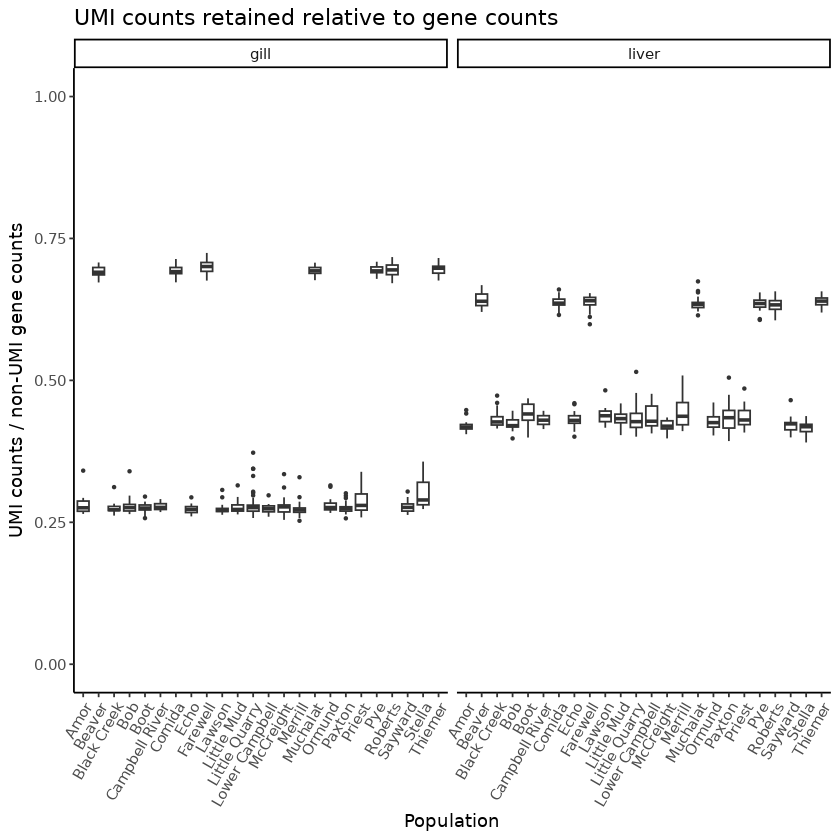

In [6]:
ratio_plot

Okay wow so there is a lot of duplication in the 2024 populations. Differences among tissues too. Definitely should use UMI counts then.

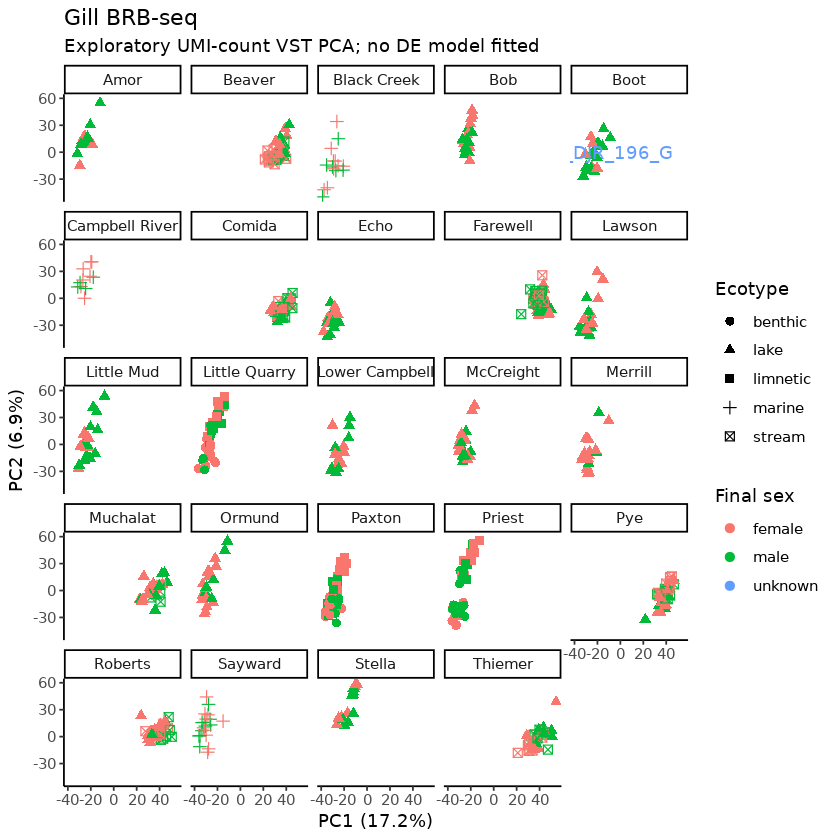

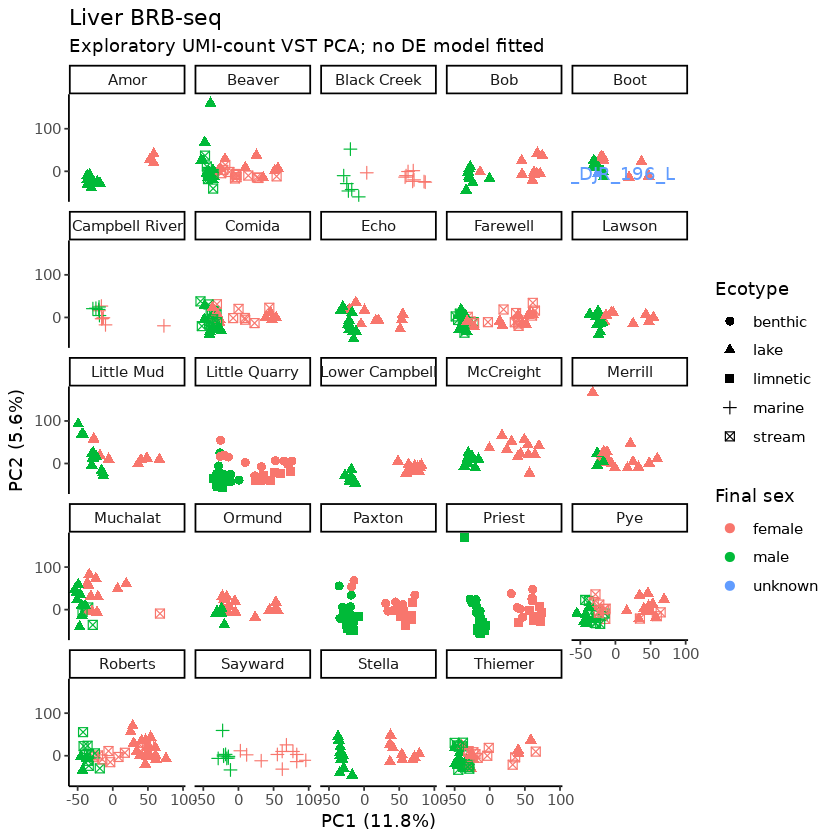

In [7]:
make_pca_data <- function(vsd_obj, metadata) {
  pca <- prcomp(t(assay(vsd_obj)), center = TRUE, scale. = FALSE)
  variance <- 100 * pca$sdev^2 / sum(pca$sdev^2)
  out <- cbind(metadata,
    PC1 = pca$x[, 1], 
    PC2 = pca$x[, 2],
    PC3 = pca$x[, 3],
    PC4 = pca$x[, 4],
    PC5 = pca$x[, 5],
    PC6 = pca$x[, 6])
  attr(out, "variance") <- variance
  out
}

gill_pca_data <- make_pca_data(gill_vsd$vsd, gill_metadata)
liver_pca_data <- make_pca_data(liver_vsd$vsd, liver_metadata)

plot_pca <- function(pca_data, title, pcs = c(1, 2)) {
  stopifnot(length(pcs) == 2, all(pcs >= 1), all(pcs == as.integer(pcs)))

  pc_x <- paste0("PC", pcs[1])
  pc_y <- paste0("PC", pcs[2])

  if (!all(c(pc_x, pc_y) %in% names(pca_data))) {
    stop("Requested PCs are not present in pca_data: ", pc_x, ", ", pc_y)
  }

  variance <- attr(pca_data, "variance")

  ggplot(pca_data, aes(x = .data[[pc_x]], y = .data[[pc_y]],
                       color = plot_sex, shape = ecotype_plot)) +
    geom_point(size = 2.2, na.rm = FALSE) +
    geom_text(
      data = pca_data[sub("_[GL]$", "", pca_data$sample_id) == "2024_DJR_196", , drop = FALSE],
      aes(label = sample_id),
      nudge_y = 0.02,
      na.rm = TRUE,
      show.legend = FALSE
    ) +
    facet_wrap(~ population) +
    labs(
      title = title,
      subtitle = "Exploratory UMI-count VST PCA; no DE model fitted",
      x = paste0(pc_x, " (", round(variance[pcs[1]], 1), "%)"),
      y = paste0(pc_y, " (", round(variance[pcs[2]], 1), "%)"),
      color = "Final sex",
      shape = "Ecotype"
    ) +
    theme_classic()
}

gill_pca_plot <- plot_pca(gill_pca_data, "Gill BRB-seq")
liver_pca_plot <- plot_pca(liver_pca_data, "Liver BRB-seq")
gill_pca_plot
liver_pca_plot
ggsave(file.path(repo_root, "vis", "BRBseq_gill_PCA.png"),
  gill_pca_plot, width = 18, height = 14, units = "in", dpi = 300)
ggsave(file.path(repo_root, "vis", "BRBseq_liver_PCA.png"),
  liver_pca_plot, width = 18, height = 14, units = "in", dpi = 300)

# Global PCA plots are regenerated below after the final metadata is loaded.

In [8]:
options(repr.plot.width = 10, repr.plot.height = 10)


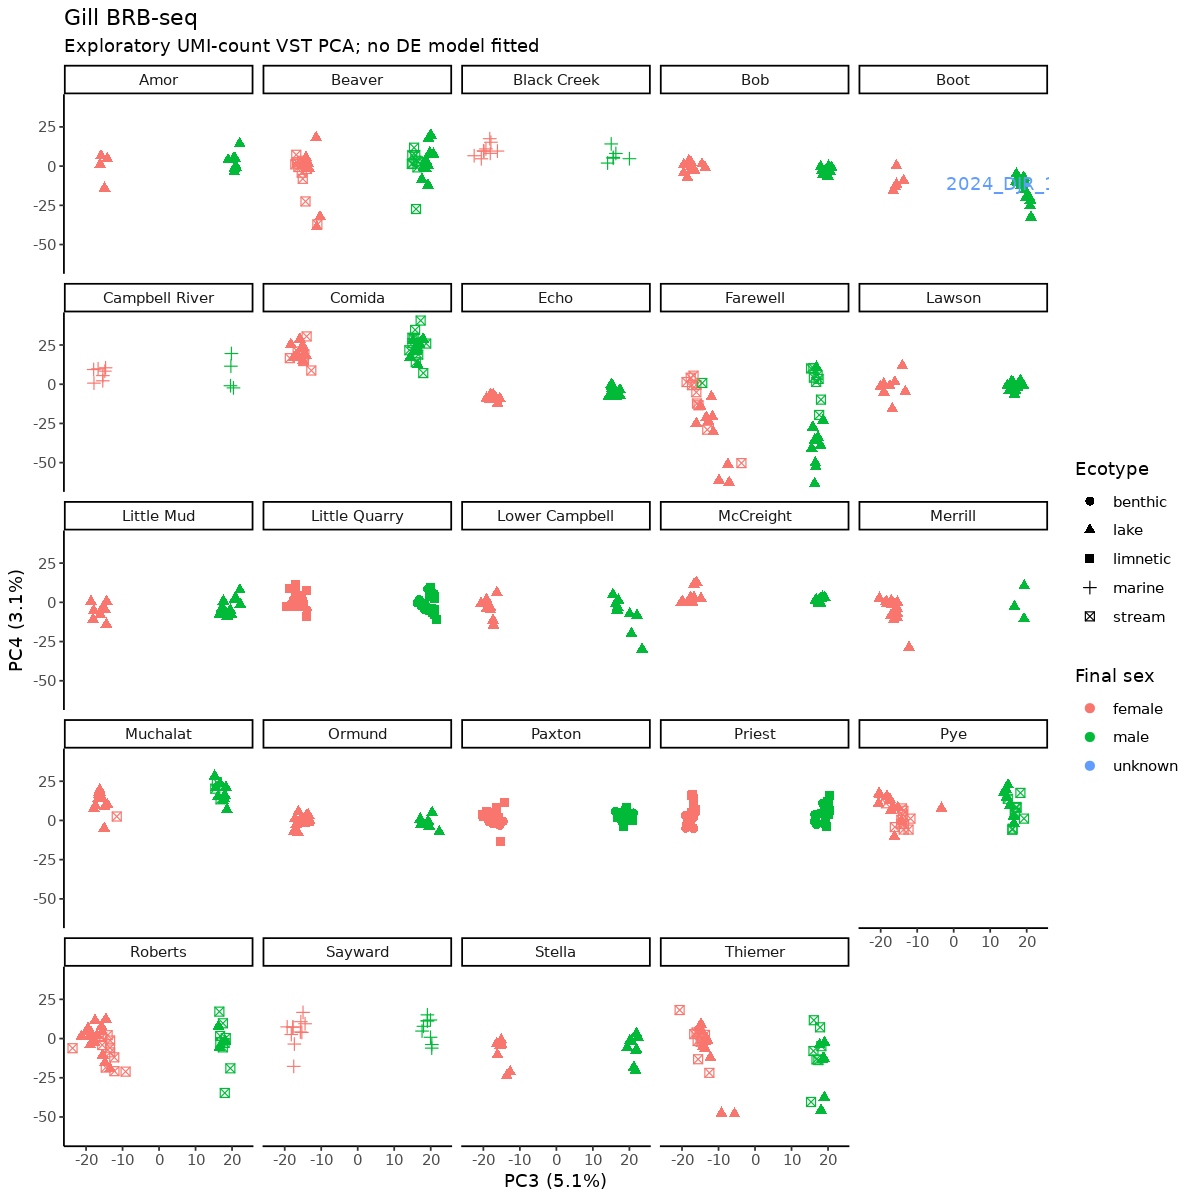

In [9]:
plot_pca(gill_pca_data, "Gill BRB-seq", pcs = c(3, 4))


Okay wow so PC3 is super diagnostic of sex in gill. 

In [10]:
require(dplyr)

Loading required package: dplyr


Attaching package: ‘dplyr’


The following object is masked from ‘package:Biobase’:

    combine


The following object is masked from ‘package:matrixStats’:

    count


The following objects are masked from ‘package:GenomicRanges’:

    intersect, setdiff, union


The following object is masked from ‘package:GenomeInfoDb’:

    intersect


The following objects are masked from ‘package:IRanges’:

    collapse, desc, intersect, setdiff, slice, union


The following objects are masked from ‘package:S4Vectors’:

    first, intersect, rename, setdiff, setequal, union


The following objects are masked from ‘package:BiocGenerics’:

    combine, intersect, setdiff, union


The following objects are masked from ‘package:stats’:

    filter, lag


The following objects are masked from ‘package:base’:

    intersect, setdiff, setequal, union




In [11]:
gill_pca_data %>% filter(PC3 < 0, final_sex == "male")

,analysis_id,original_id,source,tissue,year,barcode,source_record,mapping_note,population,site_type,⋯,final_sex_source,sex_field_mismatch,sample_id,plot_sex,PC1,PC2,PC3,PC4,PC5,PC6
,<chr>,<chr>,<chr>,<chr>,<int>,<chr>,<chr>,<chr>,<chr>,<chr>,⋯,<chr>,<lgl>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
2025_DJR_196_G,2025_DJR_196_G,2025_DJR_196,BRB,gill,2025,ACTGGAAGCCACAA,metadata/barcodes_v5D_384_brb.txt,reaction position D08; direct V5D position-to-barcode map; final gill pooling volume 1.72 uL,Farewell,stream,⋯,field,FALSE,2025_DJR_196_G,male,39.747,4.457519,-14.45844,0.7877543,4.715504,2.933559


Oh weird that its the same sample number but different years. But anyways, this is clearly a female. Just look how strongly it clusters. Let's see where this sex came from:

In [12]:
print(gill_pca_data %>% filter(PC3 < 0, final_sex == "male"))

                  analysis_id  original_id source tissue year        barcode
2025_DJR_196_G 2025_DJR_196_G 2025_DJR_196    BRB   gill 2025 ACTGGAAGCCACAA
                                   source_record
2025_DJR_196_G metadata/barcodes_v5D_384_brb.txt
                                                                                               mapping_note
2025_DJR_196_G reaction position D08; direct V5D position-to-barcode map; final gill pooling volume 1.72 uL
               population site_type      site_type_source       site_name
2025_DJR_196_G   Farewell    stream 2025 Site Type column Farewell stream
               ecotype field_population field_ecotype dna_population
2025_DJR_196_G                                                      
               dna_ecotype rna_population rna_ecotype            source_system
2025_DJR_196_G                                        2025_collection_metadata
                    base_id ecotype_plot source_analysis_id sex_call_wgs_id
2025_DJR_196

Oh okay this one doesn't have a genetic sex and the field sex is clearly wrong.

So we need to change 2025_DJR_196 to female. And then 2024_DJR_196 has to be set to male. 

### Apply PCA-reviewed sex corrections and write final metadata

Run this cell after reviewing the PCA above. Earlier analyses intentionally use the QC notebook's original sex calls.

In [13]:
sex_overrides <- data.frame(
  base_id = c("2025_DJR_196", "2024_DJR_196"),
  override_sex = c("female", "male"),
  override_note = c("Gill PCA review; field sex was male but PCA indicates female", "Gill PCA review"),
  stringsAsFactors = FALSE
)
if (!all(sex_overrides$base_id %in% tracking$base_id)) stop("PCA sex override target missing from QC metadata")
override_index <- match(tracking$base_id, sex_overrides$base_id)
has_override <- !is.na(override_index)
tracking$final_sex[has_override] <- sex_overrides$override_sex[override_index[has_override]]
tracking$final_sex_source[has_override] <- "manual_PCA_review"
if (!"final_sex_override_note" %in% names(tracking)) tracking$final_sex_override_note <- NA_character_
tracking$final_sex_override_note[has_override] <- sex_overrides$override_note[override_index[has_override]]
tracking$sex_field_mismatch <- !is.na(tracking$final_sex) & !is.na(tracking$field_sex) & tracking$final_sex != tracking$field_sex
decision_log <- rbind(decision_log, data.frame(decision = "2025_DJR_196 / 2024_DJR_196", scope = "All retained BRB tissues", action = "Set final sex female / male, respectively, by manual gill-PCA review; retain original evidence and record override source"))
write.table(tracking, file.path(derived_dir, "sample_source_mapping_FINAL_BRB.tsv"), sep = "\t", quote = FALSE, row.names = FALSE, na = "")
write.table(decision_log, file.path(derived_dir, "sample_matching_decision_log_FINAL_BRB.tsv"), sep = "\t", quote = FALSE, row.names = FALSE, na = "")
sex_columns <- c("analysis_id", "source_analysis_id", "sex_call_wgs_id", "genetic_sex", "pcr_sex", "pcr_method", "field_sex_recorded", "field_sex", "final_sex", "final_sex_source", "final_sex_override_note", "sex_field_mismatch", "sex_assignment_confident", "sex_assignment_margin", "sex_y_missing_proportion")
write.table(tracking[, sex_columns], file.path(derived_dir, "sample_genetic_sex_FINAL_BRB.tsv"), sep = "\t", quote = FALSE, row.names = FALSE, na = "")
message("Wrote final BRB metadata to ", derived_dir)

Wrote final BRB metadata to /scratch/ztobias/Gacu_BC_txmics/metadata/derived



### Get the mean freshwater divergence

In [14]:
tracking <- read.delim(
  file.path(derived_dir, "sample_source_mapping_FINAL_BRB.tsv"),
  header = TRUE, sep = "\t",
  stringsAsFactors = FALSE, check.names = FALSE
)
tracking$sample_id <- tracking$analysis_id
tracking$ecotype <- tolower(trimws(tracking$ecotype))
tracking$ecotype_plot <- tolower(trimws(tracking$ecotype_plot))
tracking$plot_sex <- ifelse(
  !is.na(tracking$final_sex) & tracking$final_sex %in% c("male", "female"),
  tracking$final_sex, "unknown"
)
tracking$pop_ecotype <- paste(tracking$population, tracking$ecotype_plot, sep = "_")

gill_metadata <- make_coldata(gill_gene_counts)
liver_metadata <- make_coldata(liver_gene_counts)

In [15]:
unique(gill_metadata$pop_ecotype)

[1] "Stella_lake"            "Echo_lake"              "Priest_limnetic"       
 [4] "Priest_benthic"         "Black Creek_marine"     "Little Quarry_benthic" 
 [7] "McCreight_lake"         "Little Quarry_limnetic" "Paxton_limnetic"       
[10] "Merrill_lake"           "Campbell River_marine"  "Little Mud_lake"       
[13] "Ormund_lake"            "Paxton_benthic"         "Bob_lake"              
[16] "Lawson_lake"            "Sayward_marine"         "Boot_lake"             
[19] "Lower Campbell_lake"    "Amor_lake"              "Beaver_lake"           
[22] "Thiemer_stream"         "Roberts_stream"         "Beaver_stream"         
[25] "Thiemer_lake"           "Comida_stream"          "Farewell_lake"         
[28] "Muchalat_stream"        "Farewell_stream"        "Comida_lake"           
[31] "Pye_lake"               "Roberts_lake"           "Muchalat_lake"         
[34] "Pye_stream"

### Make some vis with final metadata intact


In [16]:
gill_vsd <- make_vsd(gill_umi_counts, gill_metadata)
liver_vsd <- make_vsd(liver_umi_counts, liver_metadata)

converting counts to integer mode

converting counts to integer mode

-- note: fitType='parametric', but the dispersion trend was not well captured by the
   function: y = a/x + b, and a local regression fit was automatically substituted.
   specify fitType='local' or 'mean' to avoid this message next time.



In [17]:
gill_pca_data <- make_pca_data(gill_vsd$vsd, gill_metadata)
liver_pca_data <- make_pca_data(liver_vsd$vsd, liver_metadata)


#new plotting function with 196 text dropped
plot_pca <- function(pca_data, title, pcs = c(1, 2)) {
  stopifnot(length(pcs) == 2, all(pcs >= 1), all(pcs == as.integer(pcs)))

  pc_x <- paste0("PC", pcs[1])
  pc_y <- paste0("PC", pcs[2])

  if (!all(c(pc_x, pc_y) %in% names(pca_data))) {
    stop("Requested PCs are not present in pca_data: ", pc_x, ", ", pc_y)
  }

  variance <- attr(pca_data, "variance")

  ggplot(pca_data, aes(x = .data[[pc_x]], y = .data[[pc_y]],
                       color = plot_sex, shape = ecotype_plot)) +
    geom_point(size = 2.2, na.rm = FALSE) +
    facet_wrap(~ population) +
    labs(
      title = title,
      subtitle = "Exploratory UMI-count VST PCA; no DE model fitted",
      x = paste0(pc_x, " (", round(variance[pcs[1]], 1), "%)"),
      y = paste0(pc_y, " (", round(variance[pcs[2]], 1), "%)"),
      color = "Final sex",
      shape = "Ecotype"
    ) +
    theme_classic()
}


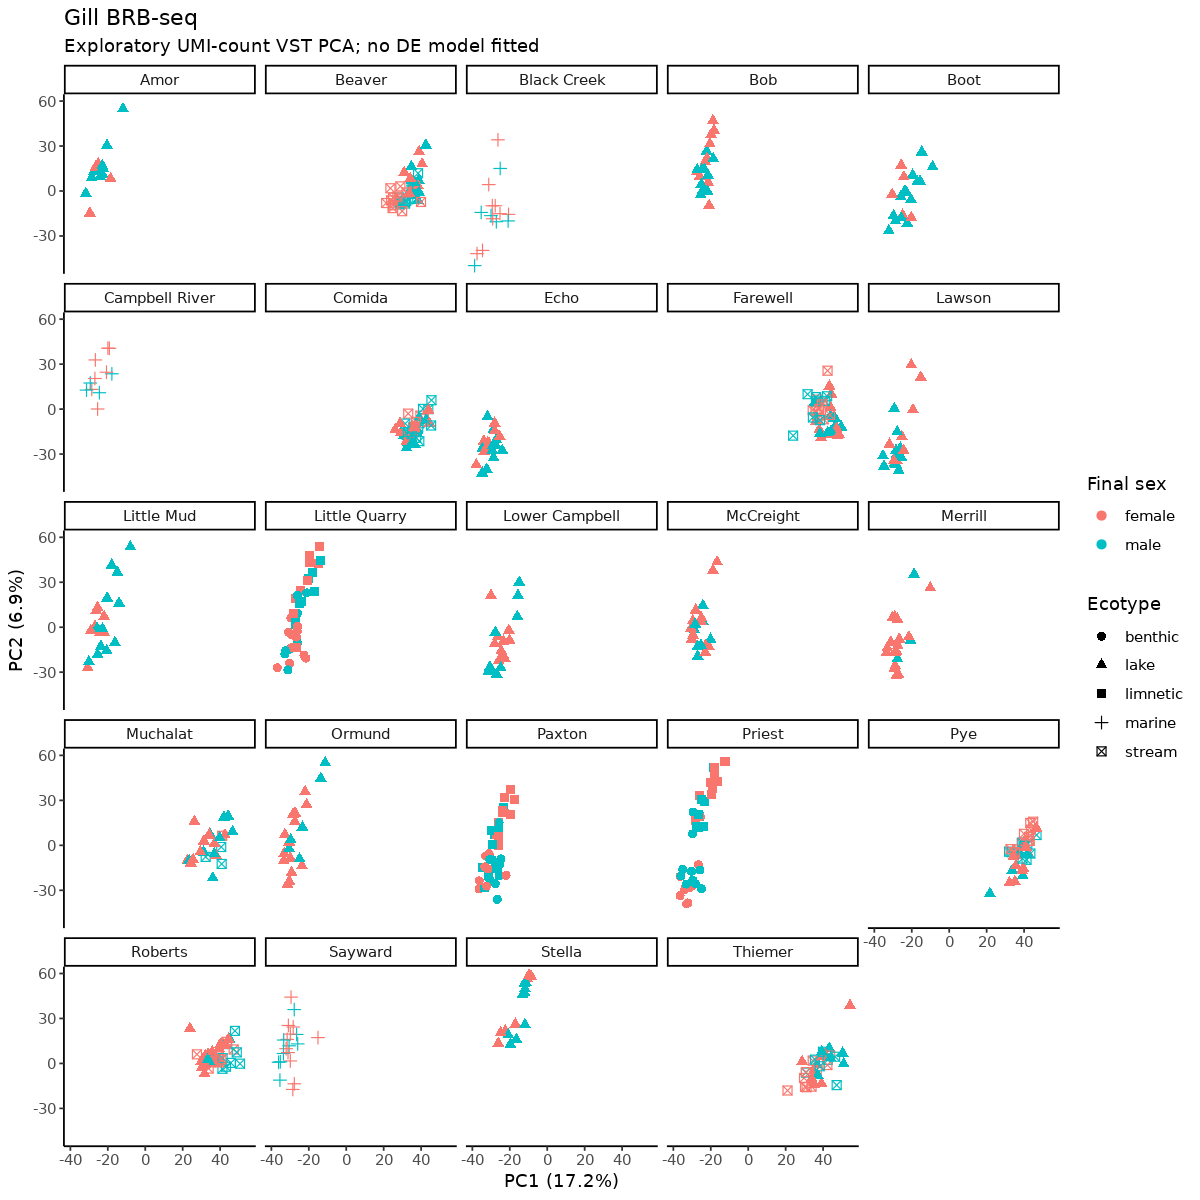

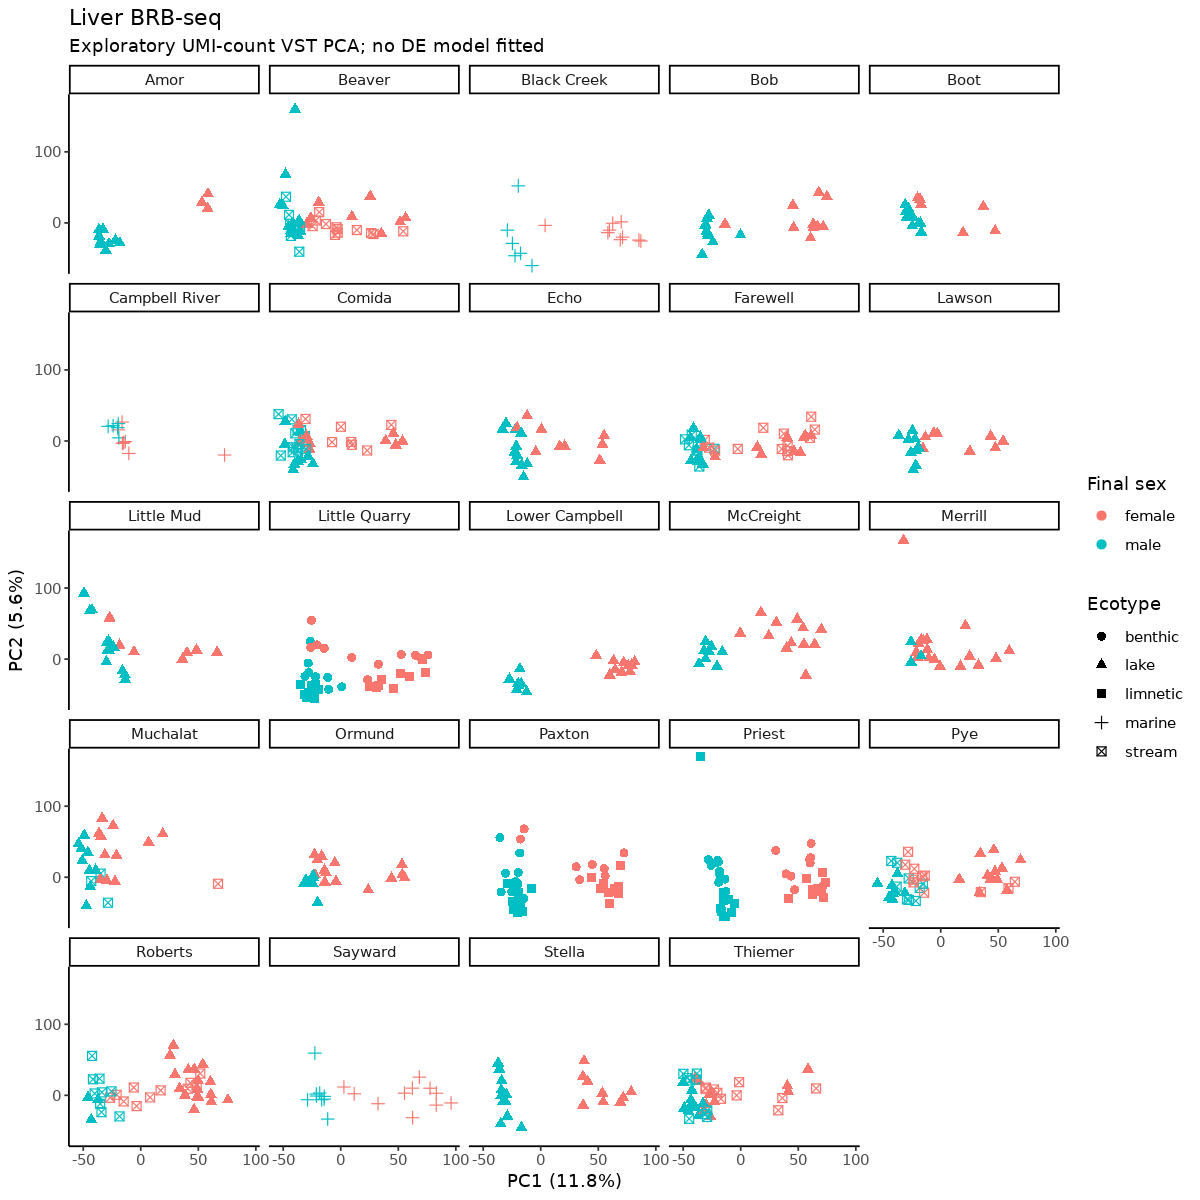

In [18]:
gill_pca_plot <- plot_pca(gill_pca_data, "Gill BRB-seq")
liver_pca_plot <- plot_pca(liver_pca_data, "Liver BRB-seq")
gill_pca_plot
liver_pca_plot
ggsave(file.path(repo_root, "vis", "BRBseq_gill_PCA_sex_corrected_1-2.png"),
  gill_pca_plot, width = 18, height = 14, units = "in", dpi = 300)
ggsave(file.path(repo_root, "vis", "BRBseq_liver_PCA_sex_corrected_1-2.png"),
  liver_pca_plot, width = 18, height = 14, units = "in", dpi = 300)

Gill PC1 strongly separates by year. Thinking this could be related to the UMI dedup. Let's look with gene counts version

In [20]:
gill_vsd_gc <- make_vsd(gill_gene_counts, gill_metadata)
liver_vsd_gc <- make_vsd(liver_gene_counts, liver_metadata)

converting counts to integer mode

converting counts to integer mode



In [21]:
gill_pca_data_gc <- make_pca_data(gill_vsd_gc$vsd, gill_metadata)
liver_pca_data_gc <- make_pca_data(liver_vsd_gc$vsd, liver_metadata)

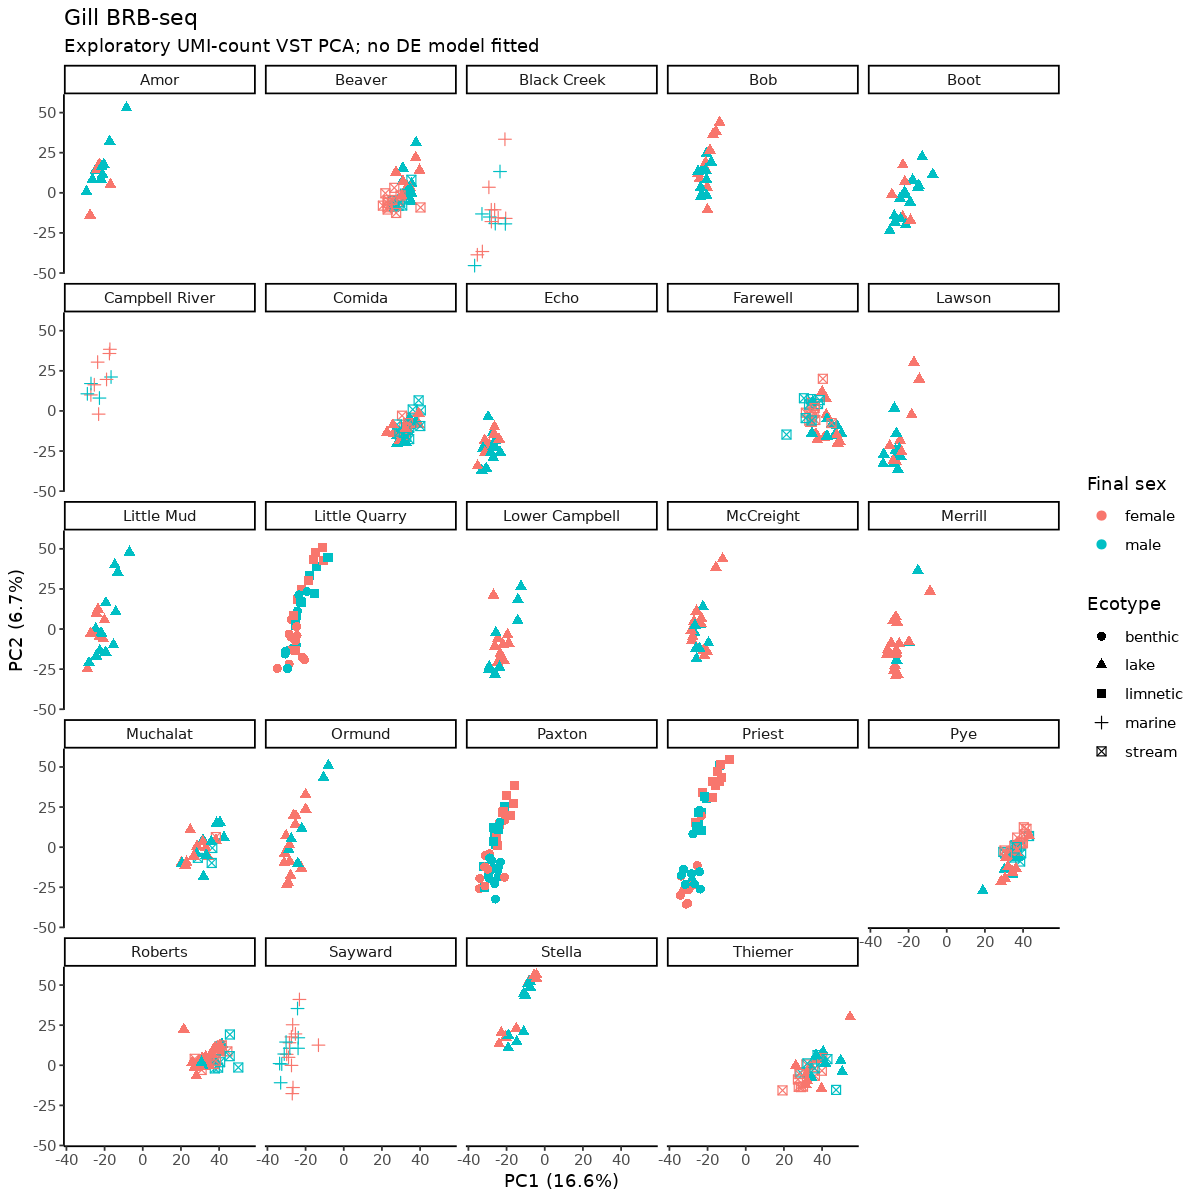

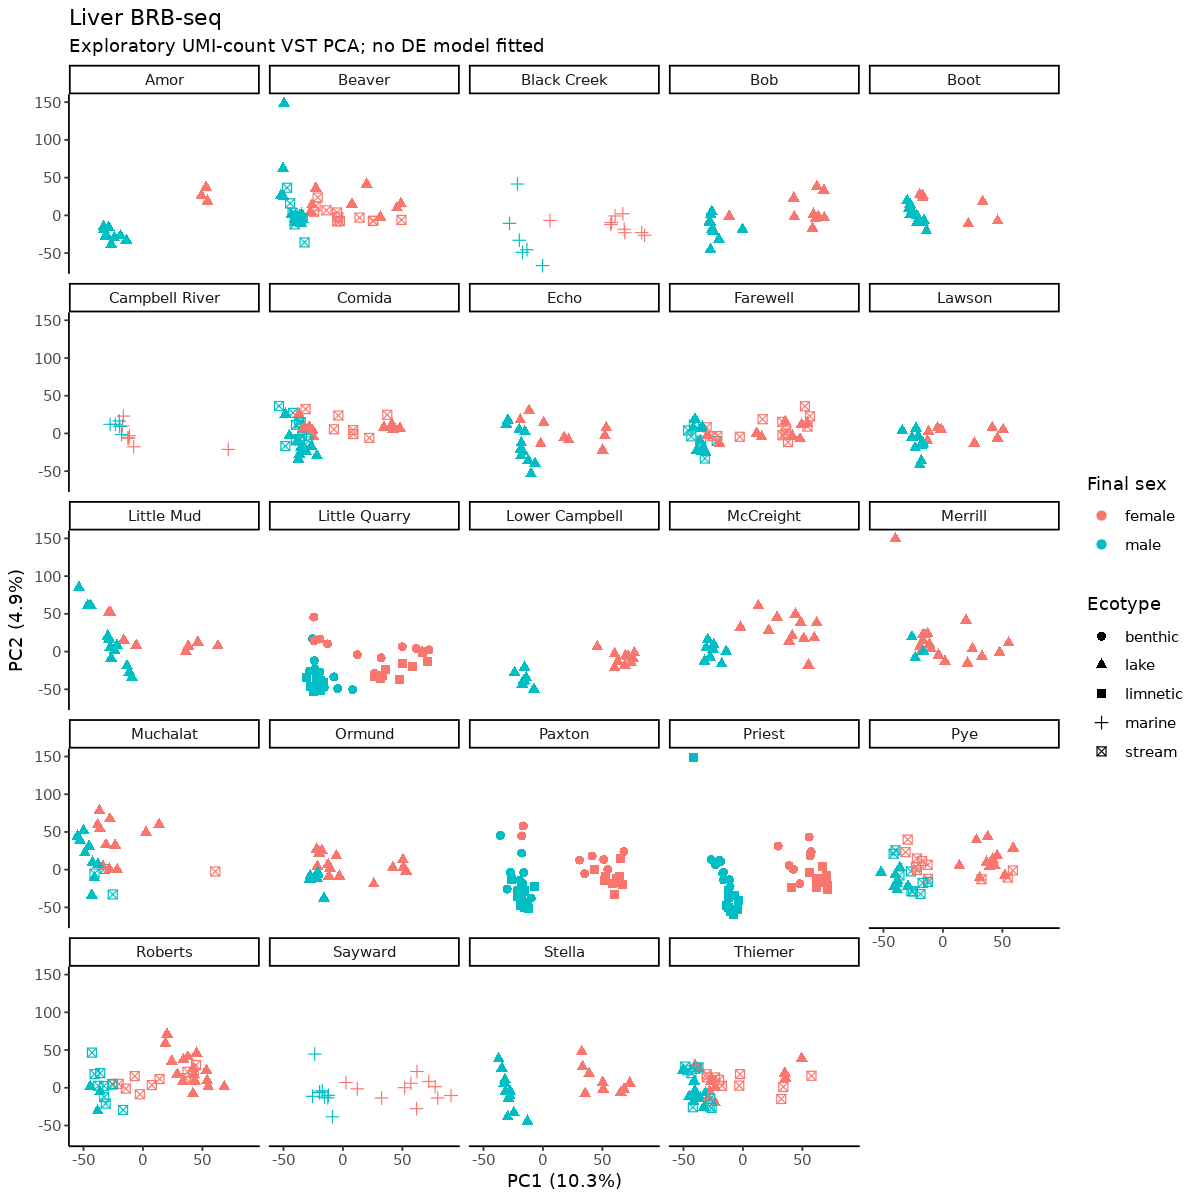

In [22]:
gill_pca_plot_gc <- plot_pca(gill_pca_data_gc, "Gill BRB-seq")
liver_pca_plot_gc <- plot_pca(liver_pca_data_gc, "Liver BRB-seq")
gill_pca_plot_gc
liver_pca_plot_gc
ggsave(file.path(repo_root, "vis", "BRBseq_gill_PCA_sex_corrected_1-2_genecounts.png"),
  gill_pca_plot_gc, width = 18, height = 14, units = "in", dpi = 300)
ggsave(file.path(repo_root, "vis", "BRBseq_liver_PCA_sex_corrected_1-2_genecounts.png"),
  liver_pca_plot_gc, width = 18, height = 14, units = "in", dpi = 300)

Hmmm okay yeah looks exactly the same.... 

Gotta figure this out....

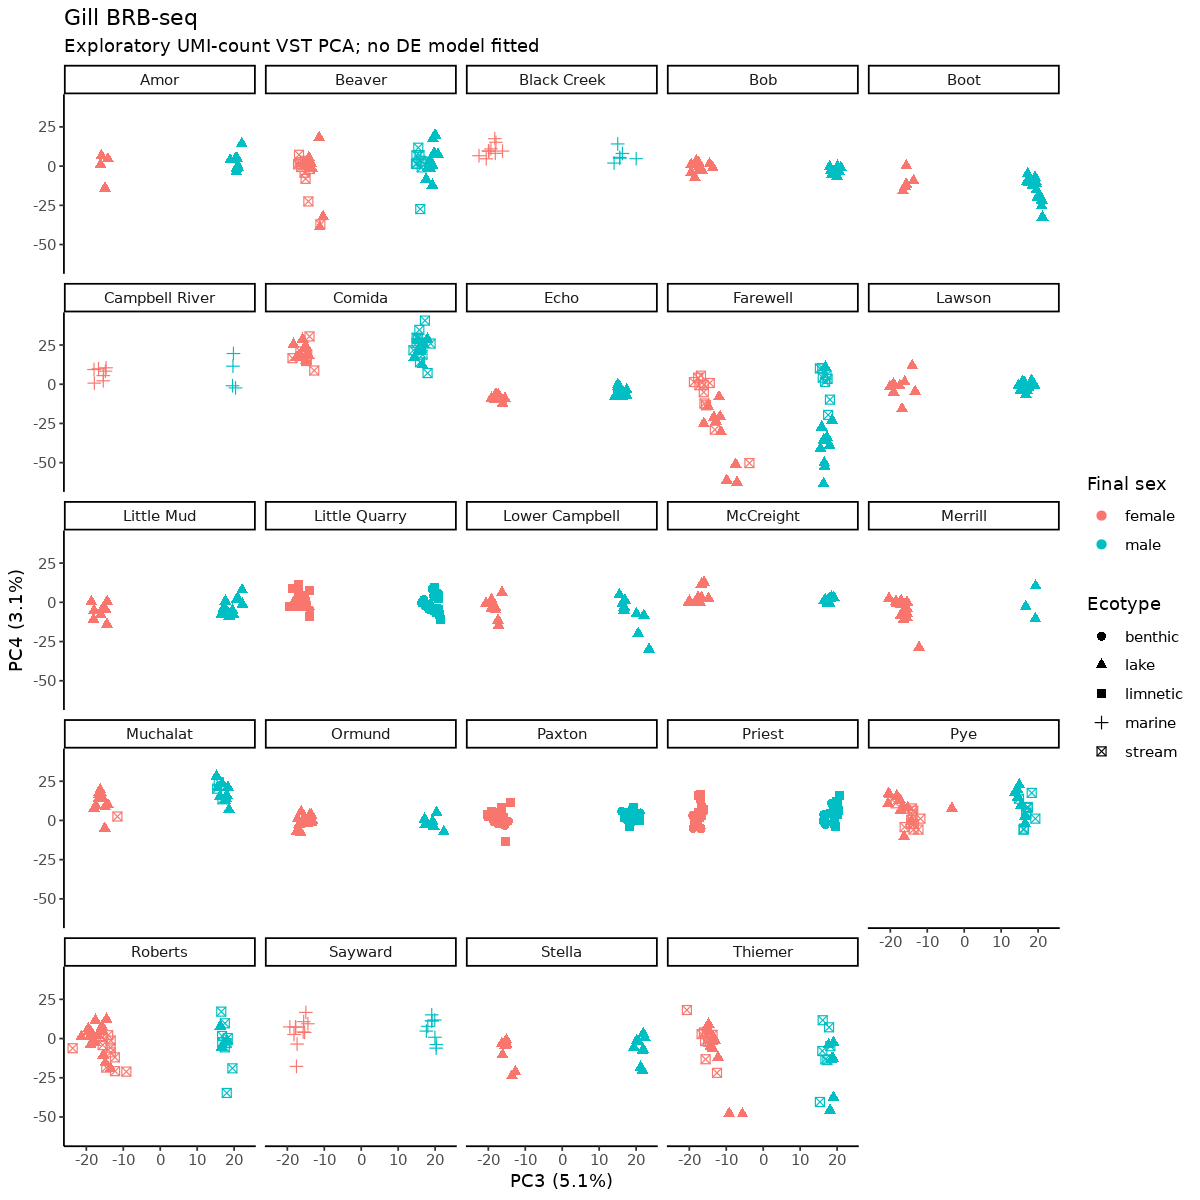

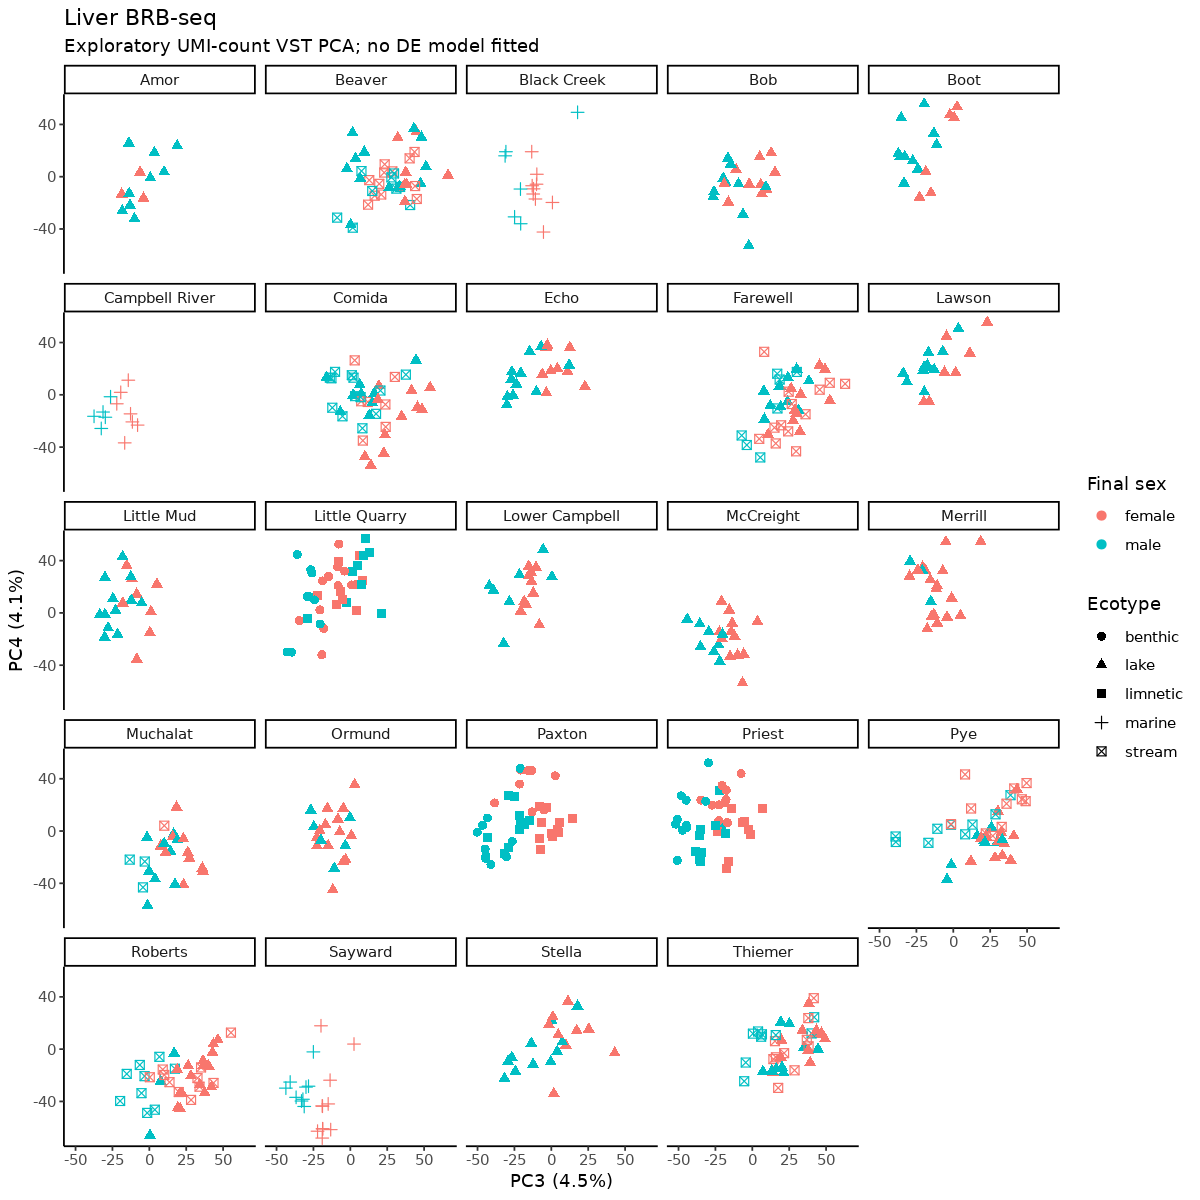

In [23]:
gill_pca_plot34 <- plot_pca(gill_pca_data, "Gill BRB-seq", pcs=c(3,4))
liver_pca_plot34 <- plot_pca(liver_pca_data, "Liver BRB-seq", pcs=c(3,4))
gill_pca_plot34
liver_pca_plot34
ggsave(file.path(repo_root, "vis", "BRBseq_gill_PCA_sex_corrected_3-4.png"),
  gill_pca_plot34, width = 18, height = 14, units = "in", dpi = 300)
ggsave(file.path(repo_root, "vis", "BRBseq_liver_PCA_sex_corrected_3-4.png"),
  liver_pca_plot34, width = 18, height = 14, units = "in", dpi = 300)

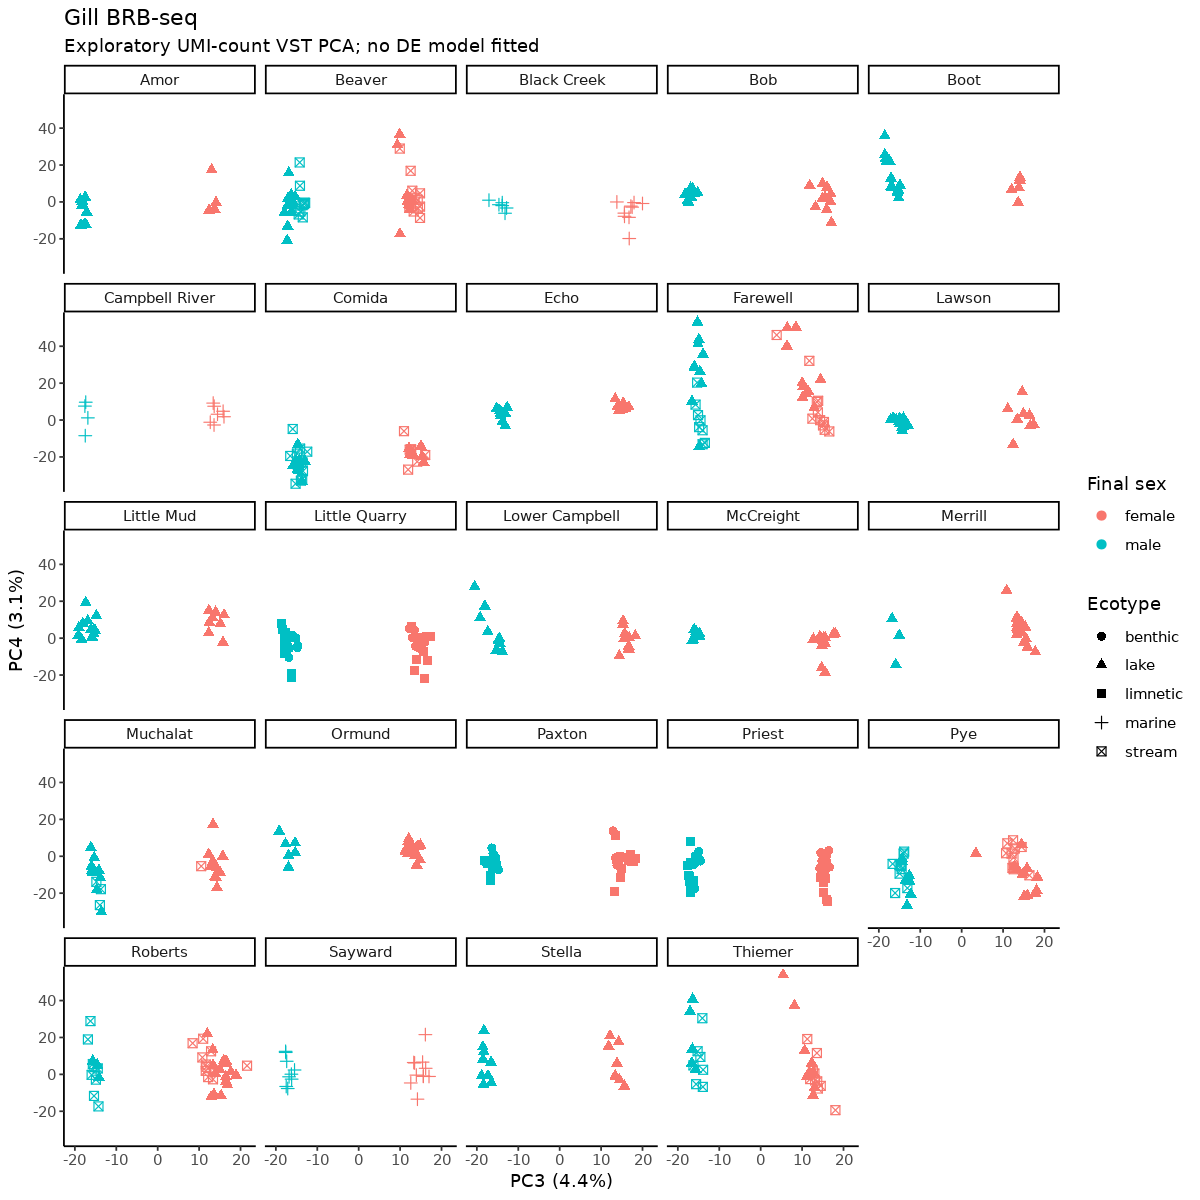

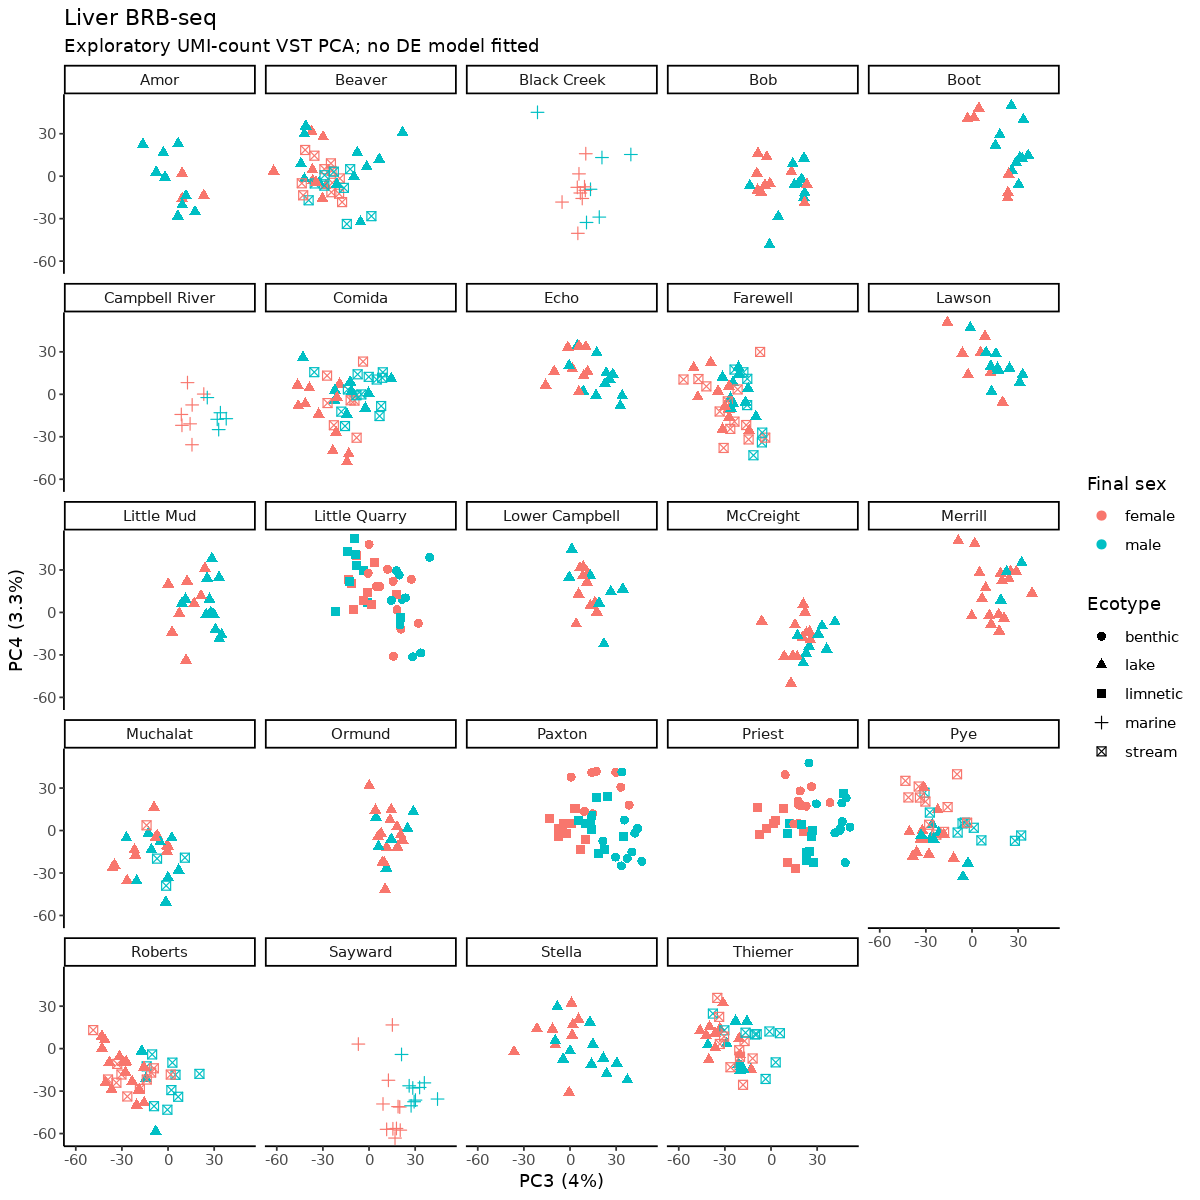

In [26]:
gill_pca_plot34_gc <- plot_pca(gill_pca_data_gc, "Gill BRB-seq", pcs=c(3,4))
liver_pca_plot34_gc <- plot_pca(liver_pca_data_gc, "Liver BRB-seq", pcs=c(3,4))
gill_pca_plot34_gc
liver_pca_plot34_gc
ggsave(file.path(repo_root, "vis", "BRBseq_gill_PCA_sex_corrected_3-4_genecounts.png"),
  gill_pca_plot34_gc, width = 18, height = 14, units = "in", dpi = 300)
ggsave(file.path(repo_root, "vis", "BRBseq_liver_PCA_sex_corrected_3-4_genecounts.png"),
  liver_pca_plot34_gc, width = 18, height = 14, units = "in", dpi = 300)

Okay yeah so for liver along PC3-4, we see this effect of year too. Doesn't seem to matter if it's UMI or gene counts. Pattern is identical. So yeah this is an issue....

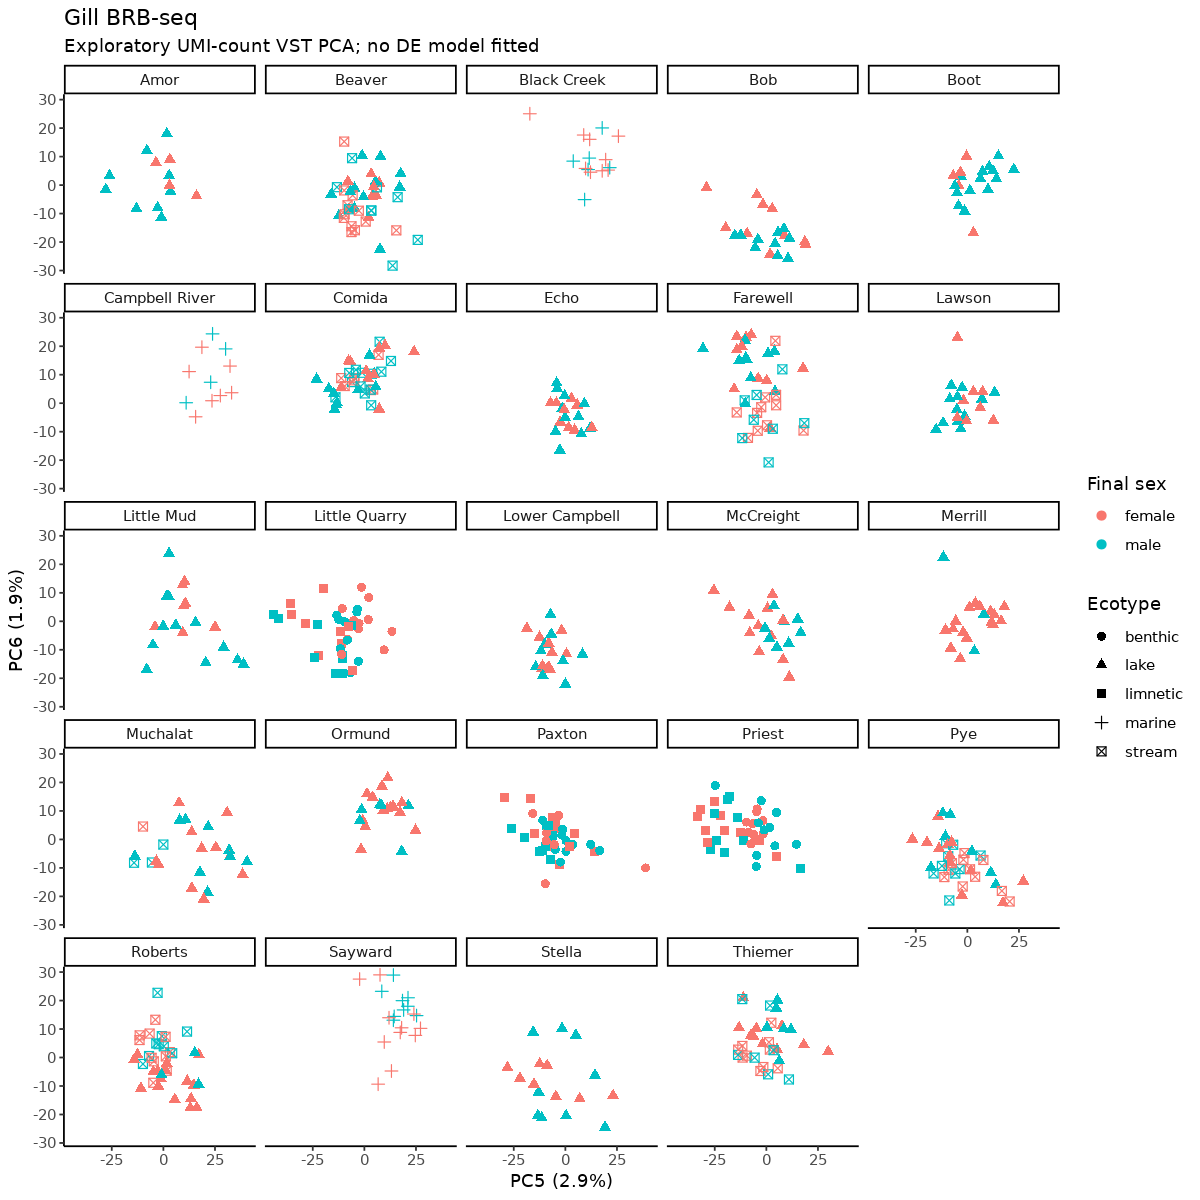

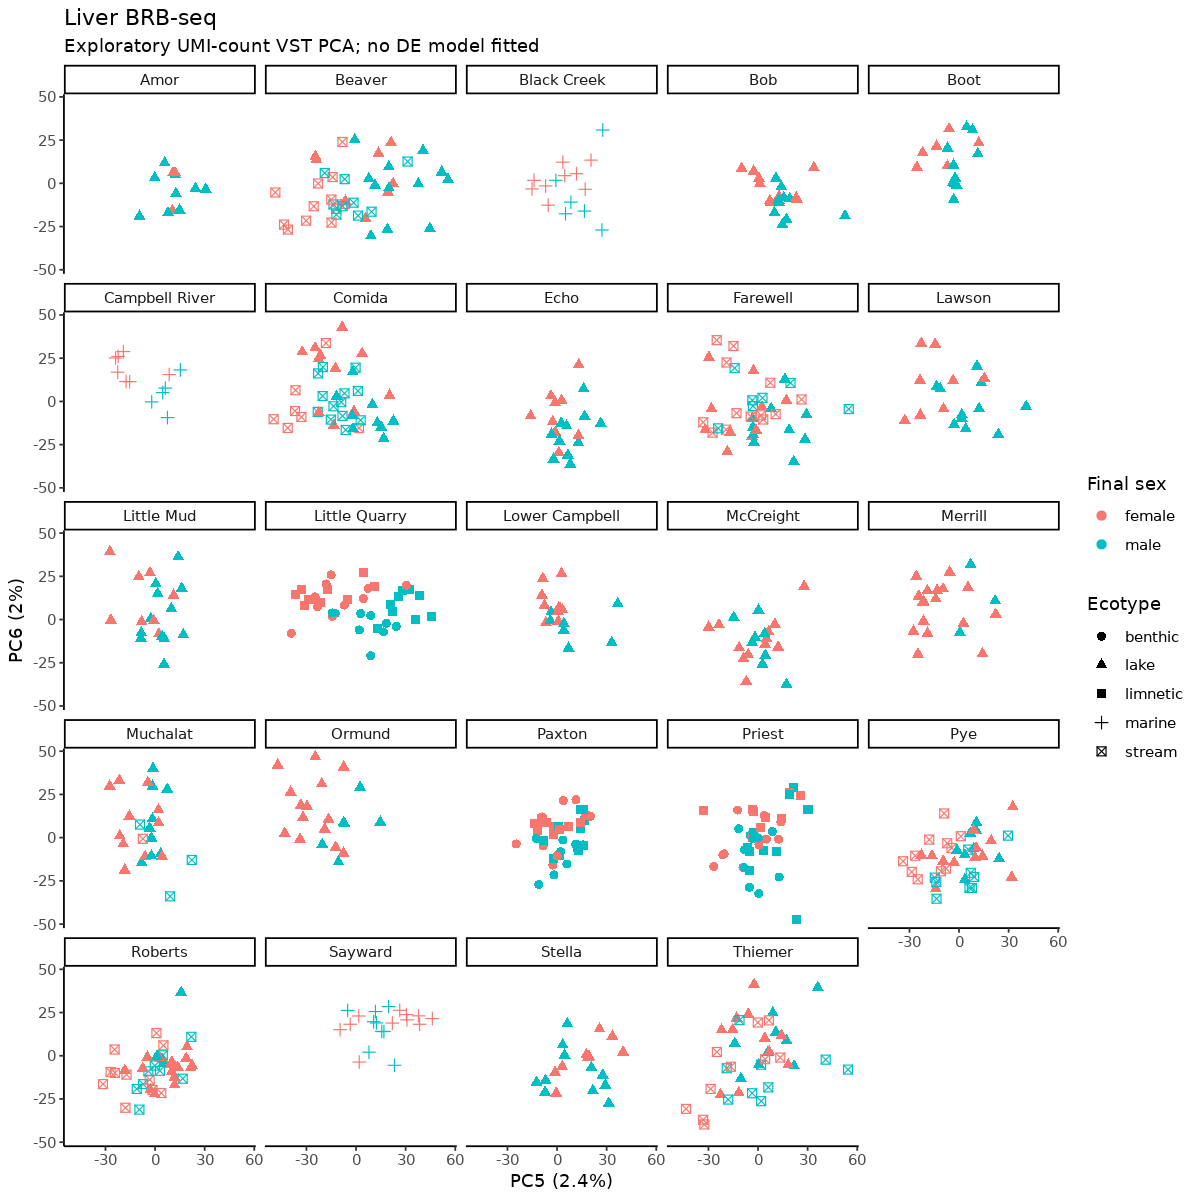

In [24]:
gill_pca_plot56 <- plot_pca(gill_pca_data, "Gill BRB-seq", pcs=c(5,6))
liver_pca_plot56 <- plot_pca(liver_pca_data, "Liver BRB-seq", pcs=c(5,6))
gill_pca_plot56
liver_pca_plot56
ggsave(file.path(repo_root, "vis", "BRBseq_gill_PCA_sex_corrected_5-6.png"),
  gill_pca_plot56, width = 18, height = 14, units = "in", dpi = 300)
ggsave(file.path(repo_root, "vis", "BRBseq_liver_PCA_sex_corrected_5-6.png"),
  liver_pca_plot56, width = 18, height = 14, units = "in", dpi = 300)

In [22]:
nrow(gill_metadata %>% filter(pop_ecotype == "Muchalat_lake"))
nrow(liver_metadata %>% filter(pop_ecotype == "Muchalat_lake"))

[1] 20

[1] 20

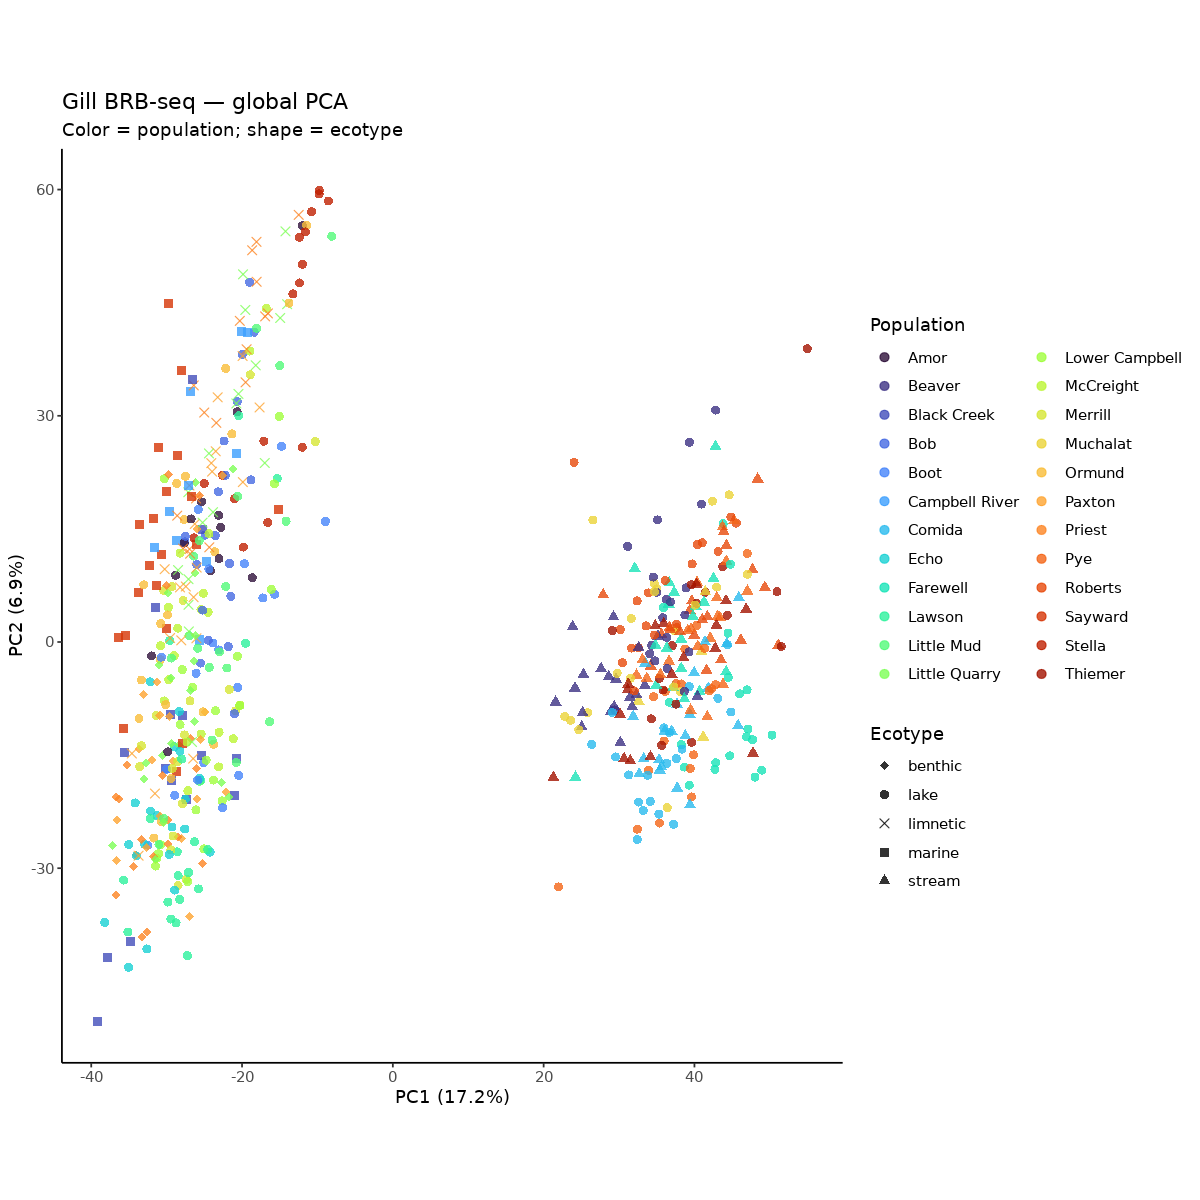

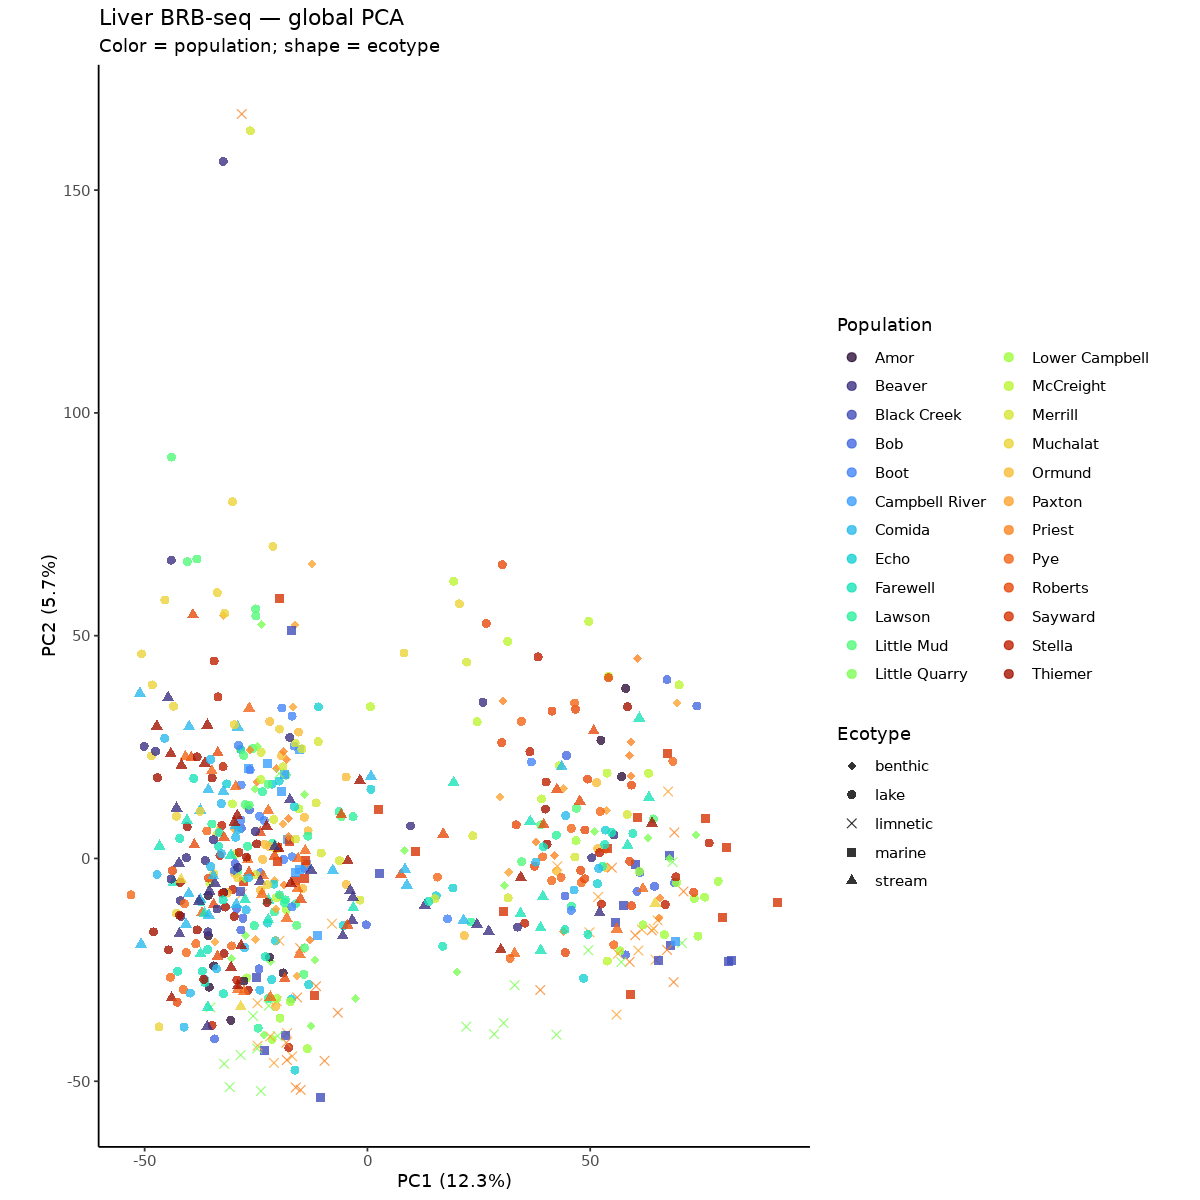

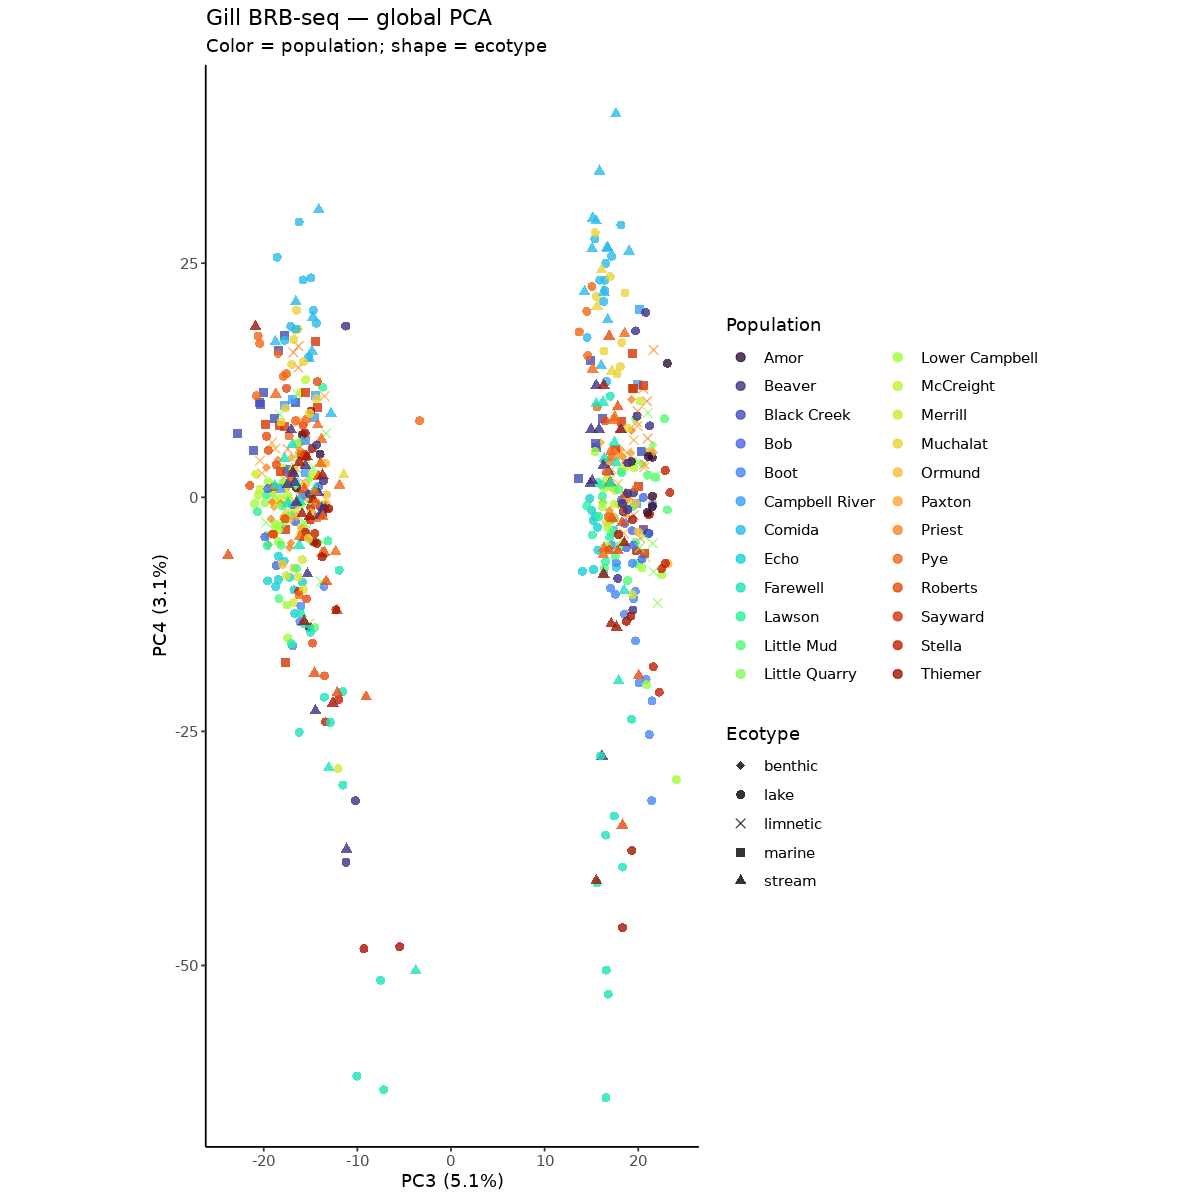

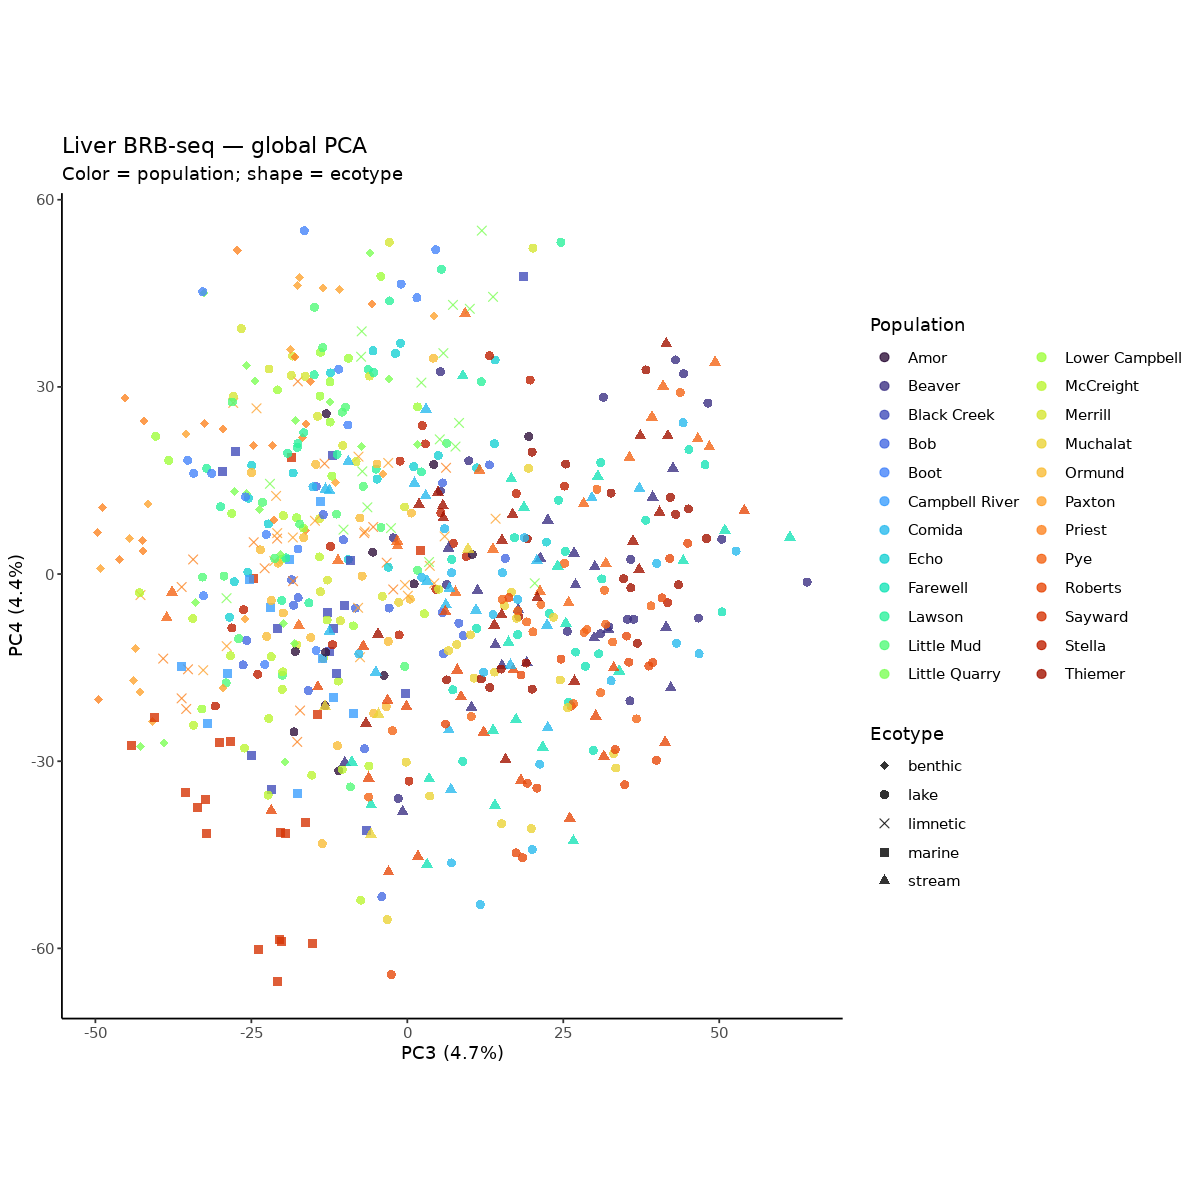

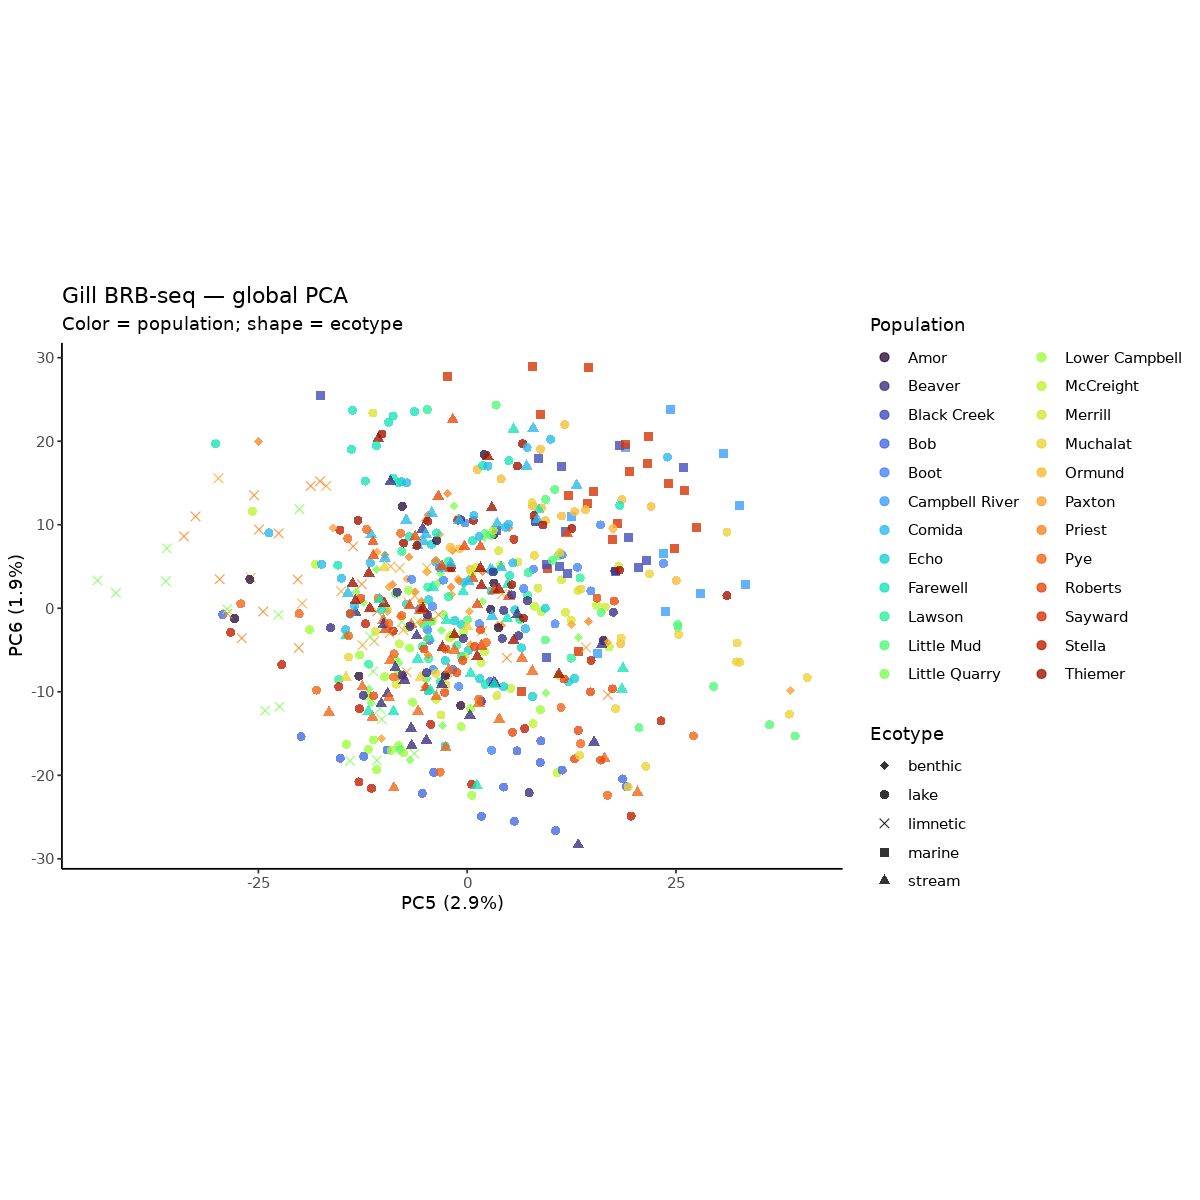

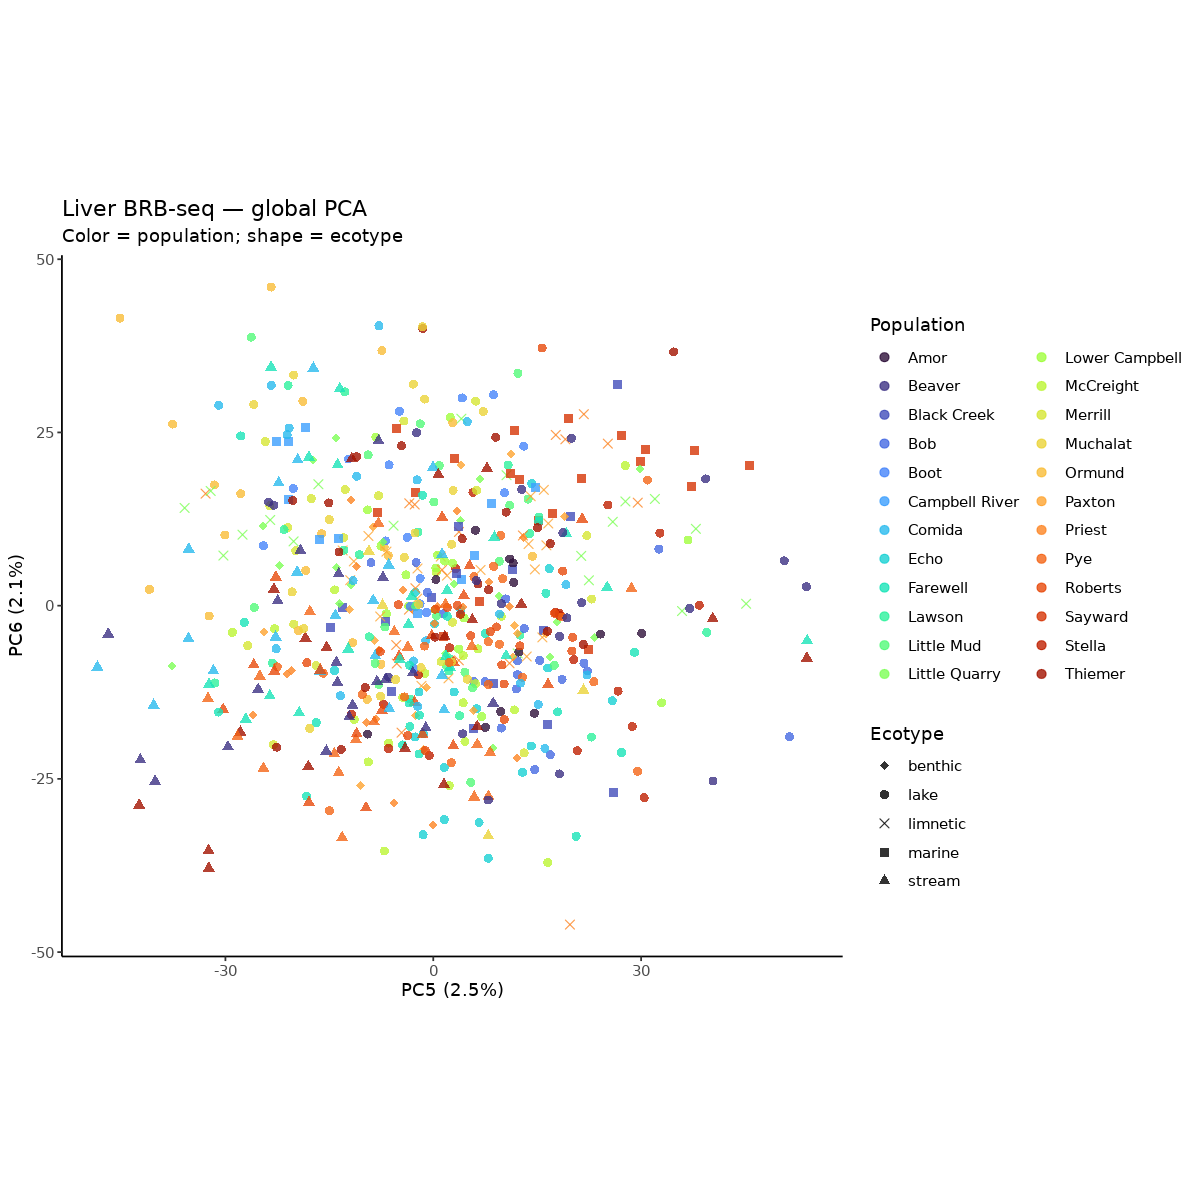

In [23]:
# Global PCA plots use the corrected metadata and PCA objects created above.
plot_pca_global <- function(pca_data, title, pcs = c(1, 2)) {
  pc_x <- paste0("PC", pcs[1])
  pc_y <- paste0("PC", pcs[2])
  if (!all(c(pc_x, pc_y) %in% names(pca_data))) {
    stop("Requested PCs are not present: ", pc_x, ", ", pc_y)
  }

  variance <- attr(pca_data, "variance")
  ggplot(pca_data, aes(x = .data[[pc_x]], y = .data[[pc_y]],
                       color = population, shape = ecotype_plot)) +
    geom_point(size = 2.2, alpha = 0.8, na.rm = TRUE) +
    scale_color_viridis_d(option = "turbo", end = 0.95) +
    scale_shape_manual(values = c(lake = 16, stream = 17, marine = 15,
                                 benthic = 18, limnetic = 4)) +
    coord_equal() +
    labs(
      title = paste0(title, " — global PCA"),
      subtitle = "Color = population; shape = ecotype",
      x = paste0(pc_x, " (", round(variance[pcs[1]], 1), "%)"),
      y = paste0(pc_y, " (", round(variance[pcs[2]], 1), "%)"),
      color = "Population", shape = "Ecotype"
    ) +
    guides(color = guide_legend(ncol = 2, order = 1),
           shape = guide_legend(order = 2)) +
    theme_classic() +
    theme(legend.position = "right")
}

pc_pairs <- list(`1-2` = c(1, 2), `3-4` = c(3, 4), `5-6` = c(5, 6))
for (pair_name in names(pc_pairs)) {
  pcs <- pc_pairs[[pair_name]]
  gill_global_pca <- plot_pca_global(gill_pca_data, "Gill BRB-seq", pcs)
  liver_global_pca <- plot_pca_global(liver_pca_data, "Liver BRB-seq", pcs)
  print(gill_global_pca)
  print(liver_global_pca)
  ggsave(file.path(repo_root, "vis", paste0("BRBseq_gill_PCA_global_PC", pair_name, ".png")),
    gill_global_pca, width = 18, height = 14, units = "in", dpi = 300)
  ggsave(file.path(repo_root, "vis", paste0("BRBseq_liver_PCA_global_PC", pair_name, ".png")),
    liver_global_pca, width = 18, height = 14, units = "in", dpi = 300)
}

Drop Muchalat stream and the admixture-identified F1/early-backcross fish listed above from the focal ecotype-divergence DE analysis. The Muchalat site has only four fish and is not representative of the other lake-stream pairs; the admixed fish are excluded to avoid treating recent hybrids/backcrosses as parental ecotype samples.

In [ ]:
admixed_base_ids <- c(
  "2025_DJR_475", "2025_DJR_464", "2024_DJR_427",
  "2024_DJR_122", "2024_DJR_109", "2024_DJR_084", "2024_DJR_045"
)

gill_drop <- gill_metadata %>%
  filter(pop_ecotype == "Muchalat_stream" | base_id %in% admixed_base_ids) %>%
  pull(sample_id)
liver_drop <- liver_metadata %>%
  filter(pop_ecotype == "Muchalat_stream" | base_id %in% admixed_base_ids) %>%
  pull(sample_id)
gill_drop
liver_drop

[1] "2025_DJR_300_G" "2025_DJR_299_G" "2025_DJR_301_G" "2025_DJR_298_G"

[1] "2025_DJR_298_L" "2025_DJR_299_L" "2025_DJR_301_L" "2025_DJR_300_L"

In [ ]:
gill_metadata <- gill_metadata %>% filter(!sample_id %in% gill_drop)
liver_metadata <- liver_metadata %>% filter(!sample_id %in% liver_drop)
gill_umi_counts <- gill_umi_counts[, !colnames(gill_umi_counts) %in% gill_drop, drop = FALSE]
liver_umi_counts <- liver_umi_counts[, !colnames(liver_umi_counts) %in% liver_drop, drop = FALSE]

In [ ]:
make_dds <- function(counts, metadata, design = ~ 0 + pop_ecotype + final_sex) {
  metadata <- metadata[match(colnames(counts), metadata$sample_id), , drop = FALSE]

  if (anyNA(metadata$sample_id)) {
    stop("Count matrix sample missing from metadata")
  }

  keep_samples <- complete.cases(metadata[, c("final_sex", "pop_ecotype")])
  counts <- counts[, keep_samples, drop = FALSE]
  metadata <- droplevels(metadata[keep_samples, , drop = FALSE])
  metadata$final_sex <- factor(metadata$final_sex)
  metadata$pop_ecotype <- factor(metadata$pop_ecotype)
  rownames(metadata) <- metadata$sample_id

  dds <- DESeqDataSetFromMatrix(
    countData = round(counts),
    colData = metadata,
    design = design
  )

  DESeq(dds)
}

In [ ]:
gill_dds <- make_dds(gill_umi_counts, gill_metadata)
liver_dds <- make_dds(liver_umi_counts, liver_metadata)

In [ ]:
saveRDS(gill_dds, "gill_dds.rds")
saveRDS(liver_dds, "liver_dds.rds")

In [ ]:
stopifnot(
  !any(colData(gill_dds)$sample_id %in% gill_drop),
  !any(colData(liver_dds)$sample_id %in% liver_drop)
)

In [27]:
resultsNames(gill_dds)

[1] "pop_ecotypeAmor_lake"              "pop_ecotypeBeaver_lake"           
 [3] "pop_ecotypeBeaver_stream"          "pop_ecotypeBlack.Creek_marine"    
 [5] "pop_ecotypeBob_lake"               "pop_ecotypeBoot_lake"             
 [7] "pop_ecotypeCampbell.River_marine"  "pop_ecotypeComida_lake"           
 [9] "pop_ecotypeComida_stream"          "pop_ecotypeEcho_lake"             
[11] "pop_ecotypeFarewell_lake"          "pop_ecotypeFarewell_stream"       
[13] "pop_ecotypeLawson_lake"            "pop_ecotypeLittle.Mud_lake"       
[15] "pop_ecotypeLittle.Quarry_benthic"  "pop_ecotypeLittle.Quarry_limnetic"
[17] "pop_ecotypeLower.Campbell_lake"    "pop_ecotypeMcCreight_lake"        
[19] "pop_ecotypeMerrill_lake"           "pop_ecotypeMuchalat_lake"         
[21] "pop_ecotypeOrmund_lake"            "pop_ecotypePaxton_benthic"        
[23] "pop_ecotypePaxton_limnetic"        "pop_ecotypePriest_benthic"        
[25] "pop_ecotypePriest_limnetic"        "pop_ecotypePye_lake"              
[27] "pop_ecotypePye_stream"             "pop_ecotypeRoberts_lake"          
[29] "pop_ecotypeRoberts_stream"         "pop_ecotypeSayward_marine"        
[31] "pop_ecotypeStella_lake"            "pop_ecotypeThiemer_lake"          
[33] "pop_ecotypeThiemer_stream"         "final_sexmale"

Now let's just get all of the non-species pair fresh to marine contrasts:

In [28]:
get_fw_marine <- function(dds) {

  pops <- levels(colData(dds)$pop_ecotype)

  freshwater <- grep("_(lake|stream)$", pops, value = TRUE)
  marine <- grep("_marine$", pops, value = TRUE)

  pairs <- expand.grid(
    freshwater = freshwater,
    marine = marine,
    stringsAsFactors = FALSE
  )

  res <- lapply(seq_len(nrow(pairs)), function(i) {

    contrast <- c(
      "pop_ecotype",
      pairs$freshwater[i],
      pairs$marine[i]
    )

    lfcShrink(
      dds,
      contrast = contrast,
      type = "ashr"
    )
  })

  names(res) <- paste(pairs$freshwater, pairs$marine, sep = "_vs_")

  res
}



In [30]:
#gill_fw_marine <- get_fw_marine(gill_dds)
#liver_fw_marine <- get_fw_marine(liver_dds)

In [31]:
#saveRDS(gill_fw_marine,"gill_fw_marine_contrasts.rds")
#saveRDS(liver_fw_marine,"liver_fw_marine_contrasts.rds")

In [32]:
gill_fw_marine <- readRDS("gill_fw_marine_contrasts.rds")
liver_fw_marine <- readRDS("liver_fw_marine_contrasts.rds")

In [33]:
gill_fw_marine <- lapply(gill_fw_marine,as.data.frame)

In [34]:
liver_fw_marine <- lapply(liver_fw_marine,as.data.frame)

In [35]:

head(gill_fw_marine[[1]])

,baseMean,log2FoldChange,lfcSE,pvalue,padj
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
LOC120823012,0.21652328,-0.0119500526,0.4803910,0.92468854,NA
LOC120816270,25.23247492,-0.3068870048,0.1379373,0.01581621,0.05673725
LOC120816259,0.71690724,-0.0333625780,0.3998939,0.85038730,0.91871599
masp1,1.22902900,0.1548607631,0.3758688,0.42917952,0.61273343
clrn1,0.03733005,-0.0008635598,0.5861470,0.98284340,NA
mindy4b,0.00935443,0.0000000000,0.5969918,1.00000000,NA


Okay let's summarize this across freshwater populations while keeping marine reference separate.

In [36]:
library(purrr)
library(tibble)

summarize_fw_marine <- function(res_list) {

  marine_pops <- unique(sub(".*_vs_", "", names(res_list)))

  setNames(lapply(marine_pops, function(marine) {

    res <- res_list[endsWith(names(res_list), paste0("_vs_", marine))]

    bind_rows(lapply(seq_along(res), function(i) {
      as.data.frame(res[[i]]) %>%
        rownames_to_column("gene") %>%
        transmute(
          gene,
          contrast = names(res)[i],
          lfc = log2FoldChange,
          sig = !is.na(padj) & padj <= 0.05
        )
    })) %>%
      group_by(gene) %>%
      summarise(
        mean_lfc = mean(lfc, na.rm = TRUE),
        median_lfc = median(lfc, na.rm = TRUE),

        n_valid = sum(!is.na(lfc)),
        n_positive = sum(lfc > 0, na.rm = TRUE),
        n_negative = sum(lfc < 0, na.rm = TRUE),
        n_zero = sum(lfc == 0, na.rm = TRUE),

        n_sig_positive = sum(sig & lfc > 0, na.rm = TRUE),
        n_sig_negative = sum(sig & lfc < 0, na.rm = TRUE),
        n_sig = sum(sig),

        direction_consistency = if_else(
          n_positive + n_negative > 0,
          pmax(n_positive, n_negative) /
            (n_positive + n_negative),
          NA_real_
        ),

        .groups = "drop"
      )

  }), marine_pops)
}

# Summarize each tissue
gill_summary <- summarize_fw_marine(gill_fw_marine)
liver_summary <- summarize_fw_marine(liver_fw_marine)

# Inspect results
names(gill_summary)
head(gill_summary[["Sayward_marine"]])

Warning message:
“package ‘purrr’ was built under R version 4.1.3”

Attaching package: ‘purrr’


The following object is masked from ‘package:GenomicRanges’:

    reduce


The following object is masked from ‘package:IRanges’:

    reduce




[1] "Black Creek_marine"    "Campbell River_marine" "Sayward_marine"

gene,mean_lfc,median_lfc,n_valid,n_positive,n_negative,n_zero,n_sig_positive,n_sig_negative,n_sig,direction_consistency
<chr>,<dbl>,<dbl>,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<dbl>
E2998_mgp01,-0.33162313,-0.03646762,24,10,14,0,6,3,9,0.5833333
E2998_mgp02,-0.96954271,-1.01227286,24,5,19,0,1,14,15,0.7916667
E2998_mgp03,-0.57369642,-0.22015603,24,5,19,0,1,8,9,0.7916667
E2998_mgp04,-0.79372774,-0.42634399,24,1,23,0,0,14,14,0.9583333
E2998_mgp05,0.06688321,0.35072560,24,19,5,0,12,2,14,0.7916667
E2998_mgp06,-0.60768052,-0.19389182,24,1,23,0,1,9,10,0.9583333


## Benthic-limnetic marine contrasts

In [37]:
# Make ecotype contrasts from the fitted population-by-ecotype model.
make_ecotype_contrasts <- function(dds) {
  groups <- levels(colData(dds)$pop_ecotype)
  freshwater <- grep("_(benthic|limnetic)$", groups, value = TRUE)
  marine <- grep("_marine$", groups, value = TRUE)
  lakes <- unique(sub("_(benthic|limnetic)$", "", freshwater))

  pairs <- list()
  add_pairs <- function(x, y, label) {
    if (length(x) && length(y)) {
      grid <- expand.grid(group1 = x, group2 = y, stringsAsFactors = FALSE)
      for (i in seq_len(nrow(grid))) {
        pairs[[paste(label, grid$group1[i], "vs", grid$group2[i], sep = "__")]] <<-
          c("pop_ecotype", grid$group1[i], grid$group2[i])
      }
    }
  }

  # Benthic/limnetic groups versus every marine population.
  add_pairs(freshwater, marine, "freshwater_marine")

  # Benthic versus limnetic within each lake that has both groups.
  for (lake in lakes) {
    benthic <- paste0(lake, "_benthic")
    limnetic <- paste0(lake, "_limnetic")
    if (all(c(benthic, limnetic) %in% groups)) {
      add_pairs(benthic, limnetic, "within_lake")
    }
  }

  # Same-ecotype comparisons between every pair of lakes.
  for (ecotype in c("benthic", "limnetic")) {
    ecotype_groups <- grep(paste0("_", ecotype, "$"), groups, value = TRUE)
    if (length(ecotype_groups) >= 2) {
      lake_pairs <- combn(ecotype_groups, 2, simplify = FALSE)
      for (pair in lake_pairs) {
        add_pairs(pair[1], pair[2], paste0(ecotype, "_across_lakes"))
      }
    }
  }

  lapply(pairs, function(contrast) lfcShrink(dds, contrast = contrast, type = "ashr"))
}

gill_ecotype_contrasts <- make_ecotype_contrasts(gill_dds)
liver_ecotype_contrasts <- make_ecotype_contrasts(liver_dds)

# Same named-list-of-DESeq-results format as the freshwater-versus-marine RDS files.
saveRDS(gill_ecotype_contrasts, "gill_ecotype_contrasts.rds")
saveRDS(liver_ecotype_contrasts, "liver_ecotype_contrasts.rds")

names(gill_ecotype_contrasts)

using 'ashr' for LFC shrinkage. If used in published research, please cite:
    Stephens, M. (2016) False discovery rates: a new deal. Biostatistics, 18:2.
    https://doi.org/10.1093/biostatistics/kxw041

using 'ashr' for LFC shrinkage. If used in published research, please cite:
    Stephens, M. (2016) False discovery rates: a new deal. Biostatistics, 18:2.
    https://doi.org/10.1093/biostatistics/kxw041

using 'ashr' for LFC shrinkage. If used in published research, please cite:
    Stephens, M. (2016) False discovery rates: a new deal. Biostatistics, 18:2.
    https://doi.org/10.1093/biostatistics/kxw041

using 'ashr' for LFC shrinkage. If used in published research, please cite:
    Stephens, M. (2016) False discovery rates: a new deal. Biostatistics, 18:2.
    https://doi.org/10.1093/biostatistics/kxw041

using 'ashr' for LFC shrinkage. If used in published research, please cite:
    Stephens, M. (2016) False discovery rates: a new deal. Biostatistics, 18:2.
    https://doi.org/

using 'ashr' for LFC shrinkage. If used in published research, please cite:
    Stephens, M. (2016) False discovery rates: a new deal. Biostatistics, 18:2.
    https://doi.org/10.1093/biostatistics/kxw041

using 'ashr' for LFC shrinkage. If used in published research, please cite:
    Stephens, M. (2016) False discovery rates: a new deal. Biostatistics, 18:2.
    https://doi.org/10.1093/biostatistics/kxw041

using 'ashr' for LFC shrinkage. If used in published research, please cite:
    Stephens, M. (2016) False discovery rates: a new deal. Biostatistics, 18:2.
    https://doi.org/10.1093/biostatistics/kxw041

using 'ashr' for LFC shrinkage. If used in published research, please cite:
    Stephens, M. (2016) False discovery rates: a new deal. Biostatistics, 18:2.
    https://doi.org/10.1093/biostatistics/kxw041

using 'ashr' for LFC shrinkage. If used in published research, please cite:
    Stephens, M. (2016) False discovery rates: a new deal. Biostatistics, 18:2.
    https://doi.org/

[1] "freshwater_marine__Little Quarry_benthic__vs__Black Creek_marine"    
 [2] "freshwater_marine__Little Quarry_limnetic__vs__Black Creek_marine"   
 [3] "freshwater_marine__Paxton_benthic__vs__Black Creek_marine"           
 [4] "freshwater_marine__Paxton_limnetic__vs__Black Creek_marine"          
 [5] "freshwater_marine__Priest_benthic__vs__Black Creek_marine"           
 [6] "freshwater_marine__Priest_limnetic__vs__Black Creek_marine"          
 [7] "freshwater_marine__Little Quarry_benthic__vs__Campbell River_marine" 
 [8] "freshwater_marine__Little Quarry_limnetic__vs__Campbell River_marine"
 [9] "freshwater_marine__Paxton_benthic__vs__Campbell River_marine"        
[10] "freshwater_marine__Paxton_limnetic__vs__Campbell River_marine"       
[11] "freshwater_marine__Priest_benthic__vs__Campbell River_marine"        
[12] "freshwater_marine__Priest_limnetic__vs__Campbell River_marine"       
[13] "freshwater_marine__Little Quarry_benthic__vs__Sayward_marine"        
[14] "freshwater_marine__Little Quarry_limnetic__vs__Sayward_marine"       
[15] "freshwater_marine__Paxton_benthic__vs__Sayward_marine"               
[16] "freshwater_marine__Paxton_limnetic__vs__Sayward_marine"              
[17] "freshwater_marine__Priest_benthic__vs__Sayward_marine"               
[18] "freshwater_marine__Priest_limnetic__vs__Sayward_marine"              
[19] "within_lake__Little Quarry_benthic__vs__Little Quarry_limnetic"      
[20] "within_lake__Paxton_benthic__vs__Paxton_limnetic"                    
[21] "within_lake__Priest_benthic__vs__Priest_limnetic"                    
[22] "benthic_across_lakes__Little Quarry_benthic__vs__Paxton_benthic"     
[23] "benthic_across_lakes__Little Quarry_benthic__vs__Priest_benthic"     
[24] "benthic_across_lakes__Paxton_benthic__vs__Priest_benthic"            
[25] "limnetic_across_lakes__Little Quarry_limnetic__vs__Paxton_limnetic"  
[26] "limnetic_across_lakes__Little Quarry_limnetic__vs__Priest_limnetic"  
[27] "limnetic_across_lakes__Paxton_limnetic__vs__Priest_limnetic"